# Trabajo Práctico Especial: Análisis de Datos Inside Airbnb (Buenos Aires 2026)

## 1. Análisis Exploratorio Inicial de la Base

### 1.1. Origen, Alcance y Naturaleza de los Datos
* **Fuente de datos (Secundaria):** Los datos provienen de *Inside Airbnb*, un proyecto independiente que extrae información pública de la plataforma Airbnb mediante técnicas de *web scraping*. Al ser recolectados por terceros sin control directo sobre el proceso de muestreo original, constituyen una fuente secundaria que requiere un análisis de calidad.
* **Temporalidad y Alcance:** El dataset representa un corte transversal (*snapshot*) de la oferta de alquileres temporarios publicados en la Ciudad Autónoma de Buenos Aires (CABA) en 2026. 
* **Confiabilidad y Calidad de los Datos:** Al tratarse de una plataforma donde los anfitriones ingresan los datos de sus anuncios a mano, la base es altamente susceptible a errores humanos. 
### 1.2. Criterios de Exclusión y Reducción Dimensional 
El dataset original constaba de 90 columnas. Para focalizar el análisis exploratorio y evitar ruido estadístico, se descartaron 64 variables agrupadas bajo los siguientes criterios metodológicos:

* **Variables Totalmente Nulas:** Atributos con 0 valores no nulos en el corte temporal de CABA (ej. `host_response_rate`, `neighbourhood_group_cleansed`, `instant_bookable`, `host_acceptance_rate`).
* **Metadatos, URLs e Identificadores Internos:** Enlaces a perfiles/fotos, IDs de extracción y timestamps del *scraper* (ej. `listing_url`, `scrape_id`, `picture_url`, `last_scraped`). No aportan capacidad explicativa al modelo de negocio.
* **Redundancia y Alta Multicolinealidad:** 
  * Temporalidad: Se descartaron las variables expresadas en meses (ej. `hosts_time_as_host_months`) dado que se conservó su equivalente exacto en años.
  * Disponibilidad y Reseñas: Se eliminaron ventanas temporales cortas (`availability_30`, `number_of_reviews_l30d`) en favor de las variables anualizadas (`availability_365`, `number_of_reviews_ltm`).
  * Calificaciones: Se suprimieron las subcategorías de puntuación (limpieza, comunicación, ubicación) para evitar multicolinealidad, conservando únicamente el promedio general (`review_scores_rating`).
  * Inventario del anfitrión: Se eliminó el desglose específico (`_entire_homes`, `_private_rooms`), reteniendo solo el total (`calculated_host_listings_count`).
* **Texto Libre Inestructurado:** Descripciones narrativas o comerciales (`name`, `description`, `host_about`) que requerirían procesamiento de lenguaje natural (NLP).
* **Varianza Cercana a Cero / Constantes:** Variables como `has_availability` (casi 100% de la base comparte el mismo valor) o `license` (apenas 486 datos válidos sobre 29.685), las cuales no otorgan poder discriminatorio estadístico.

### 1.3. Descricion de las variables
* **`id`**: Identificador único de la publicación. int64 
* **`host_id`**: Identificador único del host. int64 
* **`host_name`**: Nombre de pila del anfitrión.str
* **`hosts_time_as_user_years`**: Años de antigüedad en la plataforma como usuario. int64
* **`hosts_time_as_host_years`**: Años de experiencia operando como anfitrión. int64
* **`host_is_superhost`**: Etiqueta (verdadero/falso) que indica si el anfitrión tiene la medalla "Superhost". str
* **`neighbourhood_cleansed`**: Nombre del barrio oficial y validado estandarizadamente. str
* **`latitude`**: coordenada latitud. float64
* **`longitude`**: coordenada longitud. float64
* **`room_type`**: tipo de habitacion. str
* **`property_type`**: Tipo arquitectónico o específico de propiedad (ej. Cabaña, Loft, Departamento).  str
* **`accommodates`**: Capacidad máxima de huéspedes que pueden dormir en la propiedad. int64. Esta limitada a 16 por airbnb
* **`bathrooms`**: Cantidad numérica total de baños. float64
* **`bedrooms`**: Cantidad total de habitaciones.  float64
* **`beds`**: Cantidad total de camas.  float64
* **`amenities`**: Listado de todos los servicios y comodidades incluidos (Wifi, aire acondicionado, etc.). str
* **`price`**: Precio base diario del alquiler en formato texto (suele incluir símbolo de moneda). str
* **`minimum_nights`**: Cantidad mínima de noches exigida de forma general para poder reservar. float64
* **`maximum_nights`**: Cantidad máxima de noches permitida de forma general. Cuantitativa discreta. float64
* **`availability_365`**: Cantidad de días disponibles para reservar en los próximos 365 días. int64
* **`number_of_reviews_ltm`**: Cantidad de reseñas recibidas exclusivamente en los últimos 12 meses. int64
* **`estimated_occupancy_l365d`**: Cálculo estimado de la cantidad de días que la propiedad estuvo ocupada en el último año.int64
* **`estimated_revenue_l365d`**: Cálculo estimado de los ingresos económicos brutos generados en el último año. float64
* **`review_scores_rating`**: Puntaje promedio general del anuncio otorgado por los huéspedes. float64
* **`calculated_host_listings_count`**: Cantidad de anuncios totales del anfitrión limitados a esta misma ciudad/región. int64
* **`reviews_per_month`**: Frecuencia promedio mensual con la que la propiedad recibe reseñas. float64

### 1.4. Caracterización de los Atributos Seleccionados
Seleccionamos un subconjunto de 26 variables:

**A. Variables Cualitativas (Categóricas)**
* **Nominales:** `id`,`host_id` (estadísticamente nominal, opera como etiqueta), `host_name`, `neighbourhood_cleansed`,`room_type`, `property_type`, `amenities`.
* **Dicotómicas:** `host_is_superhost`.

**B. Variables Cuantitativas (Numéricas)**
* **Discretas:** `hosts_time_as_user_years`, `hosts_time_as_host_years`, `accommodates`, `bedrooms`,`beds`, `minimum_nights`, `maximum_nights`, `availability_365`, `number_of_reviews_ltm`, `estimated_occupancy_l365d`, `calculated_host_listings_count`.
* **Continuas:** `latitude`,`longitude`,`bathrooms`, `price`, `estimated_revenue_l365d`, `review_scores_rating`, `reviews_per_month`.

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_theme(style="whitegrid")

In [40]:

ruta_archivo = "listings.csv.gz"

df_listings = pd.read_csv(ruta_archivo, compression='gzip', low_memory=False)
print(f"Dimensiones del dataset: {df_listings.shape}")
df_listings.info()

Dimensiones del dataset: (29685, 90)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29685 entries, 0 to 29684
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            29685 non-null  int64  
 1   listing_url                                   29685 non-null  object 
 2   scrape_id                                     29685 non-null  int64  
 3   last_scraped                                  29685 non-null  object 
 4   source                                        29685 non-null  object 
 5   name                                          29685 non-null  object 
 6   description                                   28917 non-null  object 
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   29684 non-null  object 
 9   host_id                 

In [41]:
columnas_tpe = [
    'id', 'host_id', 'host_name', 'hosts_time_as_user_years', 'hosts_time_as_host_years', 
    'host_is_superhost', 'neighbourhood_cleansed','latitude', 'longitude', 'room_type', 
    'property_type', 'accommodates', 'bathrooms', 'bedrooms', 'beds', 'amenities', 
    'price', 'minimum_nights', 'maximum_nights', 'availability_365', 
    'number_of_reviews_ltm', 'estimated_occupancy_l365d', 'estimated_revenue_l365d', 
    'review_scores_rating', 'calculated_host_listings_count', 'reviews_per_month'
]
df_copia = df_listings.copy()
df_copia = df_listings[columnas_tpe]
df_copia.describe()

,id,host_id,hosts_time_as_user_years,hosts_time_as_host_years,latitude,longitude,accommodates,bathrooms,bedrooms,beds,minimum_nights,maximum_nights,availability_365,number_of_reviews_ltm,estimated_occupancy_l365d,estimated_revenue_l365d,review_scores_rating,calculated_host_listings_count,reviews_per_month
count,2.968500e+04,2.968500e+04,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000,26244.000000,24500.000000,27102.000000,29682.000000,29682.000000,29685.000000,29685.000000,29685.000000,2.788800e+04,25957.000000,29685.000000,25957.000000
mean,9.329954e+17,1.081103e+16,7.506687,5.323362,-34.592114,-58.416274,2.941654,1.244494,1.354612,1.947753,4.951722,563.329897,235.017147,12.602998,74.495873,9.570563e+06,4.780634,15.194240,1.481166
std,5.838355e+17,1.347071e+17,4.083517,4.046868,0.017920,0.030180,1.584278,0.703987,0.914463,1.621595,18.114840,430.722323,116.160445,18.157164,82.642132,2.162264e+07,0.357190,32.782011,1.640487
min,1.150800e+04,1.342600e+04,0.000000,0.000000,-34.690056,-58.530890,1.000000,0.500000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000e+00,1.000000,1.000000,0.010000
25%,6.233293e+17,3.506745e+07,4.000000,2.000000,-34.603396,-58.435972,2.000000,1.000000,1.000000,1.000000,1.000000,364.000000,148.000000,1.000000,6.000000,5.360180e+05,4.730000,1.000000,0.370000
50%,1.046350e+18,1.585246e+08,8.000000,4.000000,-34.591459,-58.418430,2.000000,1.000000,1.000000,1.000000,2.000000,365.000000,264.000000,5.000000,42.000000,4.455030e+06,4.870000,3.000000,0.980000
75%,1.431417e+18,4.644293e+08,11.000000,8.000000,-34.581430,-58.390620,4.000000,1.000000,1.000000,2.000000,3.000000,1125.000000,343.000000,18.000000,120.000000,1.316291e+07,4.980000,12.000000,2.050000
max,1.717830e+18,1.716955e+18,17.000000,15.000000,-34.534980,-58.355530,16.000000,22.000000,31.000000,50.000000,730.000000,3659.000000,365.000000,581.000000,255.000000,1.285326e+09,5.000000,208.000000,41.660000


# 2. Limpieza y preparación de la base

**Objetivo de esta sección:** implementar las operaciones de limpieza necesarias sobre la base, detallando las acciones correctivas aplicadas y justificando cada una.

**Estructura del notebook**
1. Carga y copia de trabajo
2. Variables binarias del anfitrión (`t`/`f` → booleano)
3. Valores faltantes en la configuración física (`bathrooms`, `bedrooms`, `beds`)
4. Transformación de `amenities` (filtro por varianza + One-Hot Encoding)
5. Variable objetivo price (nulos, conversión, nulos en estadía e ingresos, precios irreales)
6. Valores atípicos y reseñas.

## 2.1. Carga y copia de trabajo
Trabajamos sobre una copia (`df_copia`) para conservar la base original intacta.

In [42]:
df_copia.shape

(29685, 26)

## 2.2 Variables binarias del anfitrión
**Variables:** `host_is_superhost`

**Acción:** los valores originales eran texto (`'t'` / `'f'`). Se convirtieron a tipo booleano (`True` / `False`).

**Justificación:** son variables dicotómicas; el tipo booleano es más eficiente en memoria, evita errores de comparación entre strings y es el formato esperado por la mayoría de los métodos estadísticos y de modelado.

In [43]:
df_copia = df_copia.copy()
mapa_tf = {'t': True, 'f': False}

df_copia['host_is_superhost'] = df_copia['host_is_superhost'].map(mapa_tf)

df_copia['host_is_superhost'].value_counts()

host_is_superhost
False    17492
True     12193
Name: count, dtype: int64

## 2.3. Valores faltantes en la configuración física
**Variables:** `bathrooms`, `bedrooms`, `beds` 

### 2.3.1. Diagnóstico y mecanismo de pérdida
Se detectaron aproximadamente 3.000 nulos en `bathrooms`. Se descartó que los datos falten de forma completamente aleatoria (MCAR): se asume un mecanismo ***Missing At Random* (MAR)**, ya que la cantidad de baños esperada está directamente relacionada con la capacidad máxima de la propiedad (`accommodates`).

### 2.3.2. Decisión metodológica
* Se descartó **eliminar filas** para no perder ~10% de la muestra.
* Se descartó la **imputación global** (media/mediana de toda la columna), porque introduce valores constantes que atenúan artificialmente la variabilidad y las correlaciones.
* Se aplicó una **imputación condicional**: los nulos se reemplazan por la mediana del subgrupo de propiedades con igual capacidad. Así se rescatan los registros minimizando el impacto sobre la varianza y preservando la forma de la distribución.

### 2.3.3. Imputación condicinal
El orden refleja la dependencia real de un alojamiento y evita violar dependencias lógicas:
1. **Atributo raíz:** `accommodates` (capacidad máxima) es la variable independiente principal.
2. **Espacios:** `bathrooms` y `bedrooms`, `beds` se imputan con la mediana por `accommodates`.


In [44]:
df_copia = df_copia.copy()
df_copia['bathrooms'] = df_copia['bathrooms'].fillna(
    df_copia.groupby('accommodates')['bathrooms'].transform('median'))
df_copia['bedrooms'] = df_copia['bedrooms'].fillna(
    df_copia.groupby('accommodates')['bedrooms'].transform('median'))

df_copia[['bathrooms', 'bedrooms']].isnull().sum()
df_copia['beds'] = df_copia['beds'].fillna(df_copia.groupby('accommodates')['beds'].transform('median')).round()
# Respaldo: si algún grupo quedó todo nulo, usar la mediana global
df_copia['beds'] = df_copia['beds'].fillna(df_copia['beds'].median())

df_copia[['bathrooms', 'bedrooms', 'beds']].isnull().sum()

bathrooms    0
bedrooms     0
beds         0
dtype: int64

## 2.4. Transformación de `amenities`
**Variables generadas:** `has_refrigerator`, `has_bed_linens`, `has_elevator`, `has_parking`, `has_balcony_patio`, `has_pool`  
**Variable eliminada:** `amenities` (texto multivaluado original)

### 2.4.1. Enfoque descartado
Seleccionar las 5 comodidades más frecuentes por conteo absoluto presentaba dos problemas:
1. **Redundancia y multicolinealidad:** `Dishes and silverware`, `Cooking basics` o `Refrigerator` están casi directamente asociados a `Kitchen`, duplicando información.
2. **Bajo valor de negocio:** atributos triviales de alta frecuencia (`Hangers`, `Hot water`) no explican la variación de tarifas ni de demanda.

### 2.4.2. Exploración de frecuencias
Se limpió el formato de la lista (corchetes, comillas) y se midió el porcentaje de propiedades que posee cada comodidad agrupada mediante expresiones regulares.

In [45]:
# Frecuencia absoluta de cada comodidad individual
amenities_limpios = (df_copia['amenities']
                     .str.replace(r'\[|\]|"|\'', '', regex=True)
                     .str.split(r',\s*'))
conteo_amenities = amenities_limpios.explode().value_counts()
print("--- Top 15 amenities más frecuentes ---")
print(conteo_amenities.head(15))

--- Top 15 amenities más frecuentes ---
amenities
Kitchen                  27510
Wifi                     26707
Hot water                24117
Dishes and silverware    22694
Cooking basics           22002
Hangers                  21650
Bed linens               21637
Air conditioning         19969
Hair dryer               19805
Refrigerator             19448
Microwave                18608
TV                       18516
Bidet                    18301
Essentials               18170
Elevator                 17830
Name: count, dtype: int64


In [46]:
# Porcentaje de presencia por macro-categoría (regex)
patrones_amenities = {
    'Wifi / Internet': 'Wifi|Internet',
    'Kitchen (Cocina)': 'Kitchen',
    'TV (Cualquier tipo)': 'TV',
    'Air conditioning (AC)': r'Air conditioning|\bAC\b',
    'Hot water': 'Hot water',
    'Bed linens': 'Bed linens',
    'Refrigerator': 'Refrigerator',
    'Pool (Pileta)': 'Pool',
    'Parking (Estacionamiento)': 'Parking',
    'Gym (Gimnasio)': 'Gym',
    'Elevator (Ascensor)': 'Elevator',
    'Balcony / Patio': 'Balcony|Patio|Terrace|Backyard'
}

resultados = {nombre: df_copia['amenities'].str.contains(patron, case=False, na=False, regex=True).mean() * 100
              for nombre, patron in patrones_amenities.items()}

df_porcentajes = (pd.DataFrame(list(resultados.items()), columns=['Amenity_Agrupado', 'Porcentaje (%)'])
                  .sort_values(by='Porcentaje (%)', ascending=False)
                  .reset_index(drop=True))
display(df_porcentajes.round(2))

,Amenity_Agrupado,Porcentaje (%)
0,Wifi / Internet,99.14
1,Kitchen (Cocina),94.52
2,Air conditioning (AC),93.10
3,TV (Cualquier tipo),92.22
4,Hot water,82.68
5,Refrigerator,73.68
6,Bed linens,72.89
7,Elevator (Ascensor),60.06
8,Parking (Estacionamiento),55.94
9,Balcony / Patio,51.80


### 2.4.3. Filtro por varianza y One-Hot Encoding
Para no generar un dataset excesivamente esparso, no se codificaron todas las categorías: se aplicó un **filtro por varianza**.

* **Descartadas (varianza cercana a cero):** `Wifi` (>99%), `Air conditioning` (>93%), `Kitchen` (>94%) y `TV` (>92%). Al estar presentes en casi toda la oferta se comportan como constantes: su entropía es mínima y no aportan información para diferenciar propiedades ni justificar precios.
* **Conservadas:** `Refrigerator`, `Bed linens`, `Elevator`, `Parking`, `Balcony/Patio` y `Pool`, cuya presencia es intermedia. En ese rango la varianza y la entropía son altas, lo que da poder discriminatorio para segmentar el mercado.
* **Transformación:** las 6 comodidades se convirtieron en **variables dicotómicas (1/0)** mediante regex y se eliminó la columna original.

In [47]:
df_copia = df_copia.copy()
amenities_seleccionados = {
    'has_refrigerator': 'Refrigerator',
    'has_bed_linens': 'Bed linens',
    'has_elevator': 'Elevator',
    'has_parking': 'Parking',
    'has_balcony_patio': 'Balcony|Patio|Terrace|Backyard',
    'has_pool': 'Pool'
}

for col_name, pattern in amenities_seleccionados.items():
    df_copia[col_name] = (df_copia['amenities']
                          .str.contains(pattern, case=False, na=False, regex=True)
                          .astype(int))

# Se elimina la columna de texto original
df_copia = df_copia.drop(columns=['amenities'])
df_copia.describe()

,id,host_id,hosts_time_as_user_years,hosts_time_as_host_years,latitude,longitude,accommodates,bathrooms,bedrooms,beds,...,estimated_revenue_l365d,review_scores_rating,calculated_host_listings_count,reviews_per_month,has_refrigerator,has_bed_linens,has_elevator,has_parking,has_balcony_patio,has_pool
count,2.968500e+04,2.968500e+04,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000,...,2.788800e+04,25957.000000,29685.000000,25957.000000,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000
mean,9.329954e+17,1.081103e+16,7.506687,5.323362,-34.592114,-58.416274,2.941654,1.224583,1.295520,1.938487,...,9.570563e+06,4.780634,15.194240,1.481166,0.736837,0.728887,0.600640,0.559407,0.518039,0.269261
std,5.838355e+17,1.347071e+17,4.083517,4.046868,0.017920,0.030180,1.584278,0.672056,0.844914,1.593657,...,2.162264e+07,0.357190,32.782011,1.640487,0.440358,0.444542,0.489775,0.496467,0.499683,0.443583
min,1.150800e+04,1.342600e+04,0.000000,0.000000,-34.690056,-58.530890,1.000000,0.500000,0.000000,1.000000,...,0.000000e+00,1.000000,1.000000,0.010000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,6.233293e+17,3.506745e+07,4.000000,2.000000,-34.603396,-58.435972,2.000000,1.000000,1.000000,1.000000,...,5.360180e+05,4.730000,1.000000,0.370000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.046350e+18,1.585246e+08,8.000000,4.000000,-34.591459,-58.418430,2.000000,1.000000,1.000000,1.000000,...,4.455030e+06,4.870000,3.000000,0.980000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
75%,1.431417e+18,4.644293e+08,11.000000,8.000000,-34.581430,-58.390620,4.000000,1.000000,1.000000,2.000000,...,1.316291e+07,4.980000,12.000000,2.050000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
max,1.717830e+18,1.716955e+18,17.000000,15.000000,-34.534980,-58.355530,16.000000,22.000000,31.000000,50.000000,...,1.285326e+09,5.000000,208.000000,41.660000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## 2.5. Variable objetivo `price`
### 2.5.1. Nulos
Se detectaron **1.792 nulos**. Al ser la variable objetivo del análisis de mercado, se descartó cualquier técnica de imputación (mediana, regresión, KNN) para no introducir sesgos artificiales en su distribución. Se **eliminaron las filas** afectadas: se asume una pérdida de información menor a cambio de preservar la autenticidad de la métrica financiera.

### 2.5.2. Conversión a numérico
El precio estaba almacenado como texto con símbolo `$` y separador de miles. Se eliminaron esos caracteres con regex y se convirtió a `float`, necesario para cualquier operación aritmética o estadística.

### 2.5.3 Eliminación de filas con nulos en estadía e ingresos
**Variables:** `minimum_nights`, `maximum_nights`, `estimated_revenue_l365d`

**Acción:** se eliminaron las filas con nulos en estas variables.

**Justificación:** la cantidad de nulos es baja y se trata de variables sin una variable auxiliar confiable para imputar. En `estimated_revenue_l365d`, además, el valor deriva de `price` y de la ocupación estimada, por lo que imputarlo generaría datos artificiales sobre una métrica financiera.
### 2.5.4. Precios irreales

Al ordenar por ingreso anual estimado, los primeros puestos tenían precios por noche de entre $1,9 M y $171,6 M, valores no plausibles para un alquiler en Buenos Aires (probables errores de carga). Como `estimated_revenue_l365d = price × ocupación`, un solo precio erróneo genera un ingreso "récord" falso que distorsiona las medias y los modelos. En el otro extremo, los precios más bajos (p. ej. $2.385 por noche con una mediana de $100.000) también eran inverosímiles y tenían ocupación 0.

Se aplicó el criterio del boxplot para valores extremos, pero **sobre ln(price)**: se eliminaron los precios fuera de las cercas **Q1 − 3·IQR** y **Q3 + 3·IQR** (calculadas en logaritmo). El precio crece de forma multiplicativa (un alquiler caro cuesta varias veces el típico), así que en escala logarítmica los límites equivalen a "N veces la mediana" y no a un monto fijo. Probar la regla directamente sobre el precio crudo eliminaba el 4,24 % de la base (límite $336.413), una proporción demasiado alta para ser solo errores de carga, que habría sacado alojamientos caros pero reales. La regla es la misma para toda la base.

**Resultado:** con una mediana de $100.612, las cercas quedaron en $11.589 y $912.069 por noche (≈ 0,12 y 9,1 veces la mediana). Se eliminaron **294 filas (1,05 %)**: 67 por debajo y 227 por encima. El rango conservado va de $12.124 a $894.376, valores extremos pero plausibles (alojamientos muy económicos y de lujo). El ingreso estimado no necesita limpieza aparte porque deriva de `price`.

In [48]:
df_copia = df_copia.dropna(subset=['price'])
print("Nulos restantes en 'price':", df_copia['price'].isnull().sum())

df_copia['price'] = df_copia['price'].str.replace(r'[\$,]', '', regex=True).astype(float)
df_copia['price'].describe()

df_copia = df_copia.dropna(subset=['minimum_nights', 'maximum_nights'])
df_copia = df_copia.dropna(subset=['estimated_revenue_l365d'])
df_copia.shape

Nulos restantes en 'price': 0


(27885, 31)

In [49]:
lp = np.log(df_copia.loc[df_copia["price"] > 0, "price"])
q1, q3 = lp.quantile([.25, .75])
lim_inf, lim_sup = np.exp(q1 - 3*(q3 - q1)), np.exp(q3 + 3*(q3 - q1))

n0 = len(df_copia)
n_bajo = (df_copia["price"] < lim_inf).sum(); n_alto = (df_copia["price"] > lim_sup).sum()
print(f"Mediana: {df_copia['price'].median():,.0f}")
df_copia = df_copia[df_copia["price"].between(lim_inf, lim_sup)].copy()
print(f"Cercas: [{lim_inf:,.0f} ; {lim_sup:,.0f}] | eliminados: {n0-len(df_copia)} ({(n0-len(df_copia))/n0:.2%}) | por debajo: {n_bajo} | por encima: {n_alto} | filas: {len(df_copia)}")
print(f"Precio conservado: mín {df_copia['price'].min():,.0f} | máx {df_copia['price'].max():,.0f}")

Mediana: 100,612
Cercas: [11,589 ; 912,069] | eliminados: 294 (1.05%) | por debajo: 67 | por encima: 227 | filas: 27591
Precio conservado: mín 12,124 | máx 894,376


### 2.6. Tratamiento de valores atípicos y variables de reseñas

#### 2.6.1. Valores extremos en `maximum_nights`

**Variable:** `maximum_nights`

**Diagnóstico.** El percentil 99 coincide con 1125 noches (≈ 3 años), valor que funciona como tope de la variable: solo 11 anuncios (0,04 %) lo superan.

**Regla.** Se eliminan los anuncios con `maximum_nights` > 1125. No se usa el percentil como criterio, sino el tope observado en los datos: lo que lo supera es inconsistente con el resto de la base.

**Resultado.** 11 anuncios eliminados (0,04 %); la base pasa de 27.591 a 27.580 filas. El efecto sobre el análisis es mínimo.

#### 2.6.2. Conservación de `number_of_reviews_ltm`

**Diagnóstico.** El percentil 99 es 80 reseñas en los últimos 12 meses y 273 anuncios (0,99 %) lo superan.

**Decisión.** No se recorta. Por tres motivos:
- Recortar en un percentil elimina siempre alrededor del 1 % de la base, haya o no errores.
- Más de 80 reseñas en un año (más de una por semana) es una actividad alta pero plausible, no un error de carga.
- `estimated_occupancy_l365d` se calcula a partir de las reseñas: eliminar estos anuncios sacaría justamente a los más ocupados y sesgaría la ocupación a la baja.

#### 2.6.3. Preservación de nulos estructurales en reseñas

**Variables:** `review_scores_rating`, `reviews_per_month`

Estas variables presentan nulos que responden a una ausencia lógica de datos (anuncios sin reseñas en el período). Se decidió **no aplicar ninguna técnica de imputación** para mantener la fidelidad de la métrica. Imputarlos asignaría calificaciones artificiales a propiedades no probadas por el mercado y sesgaría el análisis de reputación.

#### 2.6.4. Valores que se conservan

No se eliminó información real aunque parezca extrema:
- **Ocupación = 0 días (22,3 % de la base):** anuncios sin reseñas en el último año. Es información, no error.
- **Ocupación en el tope de 255 días (7,8 %):** límite del método de estimación, no un dato mal cargado.
- **`minimum_nights` altos:** el 99 % de los anuncios exige 30 noches o menos (mediana: 2). 390 anuncios piden exactamente 30 (formato mensual) y 224 (0,81 %) piden más de 30, hasta un máximo de 365. Ningún anuncio tiene `minimum_nights` mayor que `maximum_nights`. Describen oferta real de mediano plazo, no errores de carga.
- **Precios extremos pero plausibles:** los errores de carga ya se eliminaron en 2.5.4. Se conservan precios de $12.124 a $894.376 por noche.

Los percentiles se usan únicamente para recortar la escala de los gráficos, nunca para eliminar filas.

In [50]:
print("--- maximum_nights: valores extremos ---")
mx = df_copia["maximum_nights"]
print(f"p99: {mx.quantile(.99):.0f} | por encima de 1125: {(mx > 1125).sum()} ({(mx > 1125).mean():.2%})")

--- maximum_nights: valores extremos ---
p99: 1125 | por encima de 1125: 11 (0.04%)


In [51]:
n0 = len(df_copia)
df_copia = df_copia[df_copia["maximum_nights"] <= 1125].copy()
print(f"Filas antes: {n0} | después: {len(df_copia)} | eliminadas: {n0 - len(df_copia)}")

Filas antes: 27591 | después: 27580 | eliminadas: 11


### 3. Distribución de Variables: Comportamiento y Asimetrías

Salvo la latitud, los histogramas muestran distribuciones muy alejadas de la normal: colas largas a la derecha, valores "redondos" por defecto de la plataforma y picos en valores extremos. Varias variables se grafican con zoom por percentil (p95 a p99), por lo que sus colas reales son más largas que lo visible.

#### 3.1. Variables con Fuerte Asimetría Positiva (Sesgo a la Derecha)
* **Precio e ingreso (`price`, `estimated_revenue_l365d`):** `price` tiene la moda entre $80.000 y $100.000 y una cola hacia propiedades premium (el gráfico se corta en p95, ≈ $280.000). El ingreso está inflado en cero (6.156 anuncios, 22 %), la gran mayoría queda por debajo de ~$30 millones anuales y la cola llega a ~$200 millones.
* **Capacidad (`accommodates`, `bedrooms`, `bathrooms`):** la oferta es mayormente de departamentos chicos. `accommodates` tiene la moda en 2 personas (~13.300 anuncios) y un segundo escalón en 4. `bedrooms` y `bathrooms` se concentran en 1, con caídas fuertes desde 2.
* **Anfitrión y reglas (`calculated_host_listings_count`, `minimum_nights`):** domina el anfitrión de 1 propiedad (~10.000 anuncios), seguido por el de 2. La cola (el gráfico se corta en p95, ≈ 72 propiedades) corresponde a agencias e inversores. `minimum_nights` se concentra en 1 a 3 noches, con picos en valores redondos (7, 15, 30).
* **Antigüedad como anfitrión (`hosts_time_as_host_years`):** moda en 2-3 años, muchos anfitriones nuevos (~0 años), un pico secundario cerca de los 7 y una cola hasta 15 años.
* **Actividad (`number_of_reviews_ltm`, `reviews_per_month`):** ambas se concentran cerca de 0. Unos 21.000 anuncios tienen menos de 20 reseñas en el último año y la gran mayoría recibe menos de 3 reseñas por mes.
* **Ocupación (`estimated_occupancy_l365d`):** gran masa en 0-10 días (~7.700 anuncios) y decaimiento progresivo. Es una estimación y no un dato observado: el pico en ~255 días refleja el tope del 70 % (0,7 × 365 ≈ 255) que Inside Airbnb aplica en su modelo, no un comportamiento real.

#### 3.2. Variables con Asimetría Negativa (Sesgo a la Izquierda)
* **Reputación (`review_scores_rating`):** casi toda la masa está entre 4,5 y 5, con la moda en 5.
* **Disponibilidad (`availability_365`):** el pico dominante está en 365 días (~5.400 anuncios siempre abiertos). El resto es irregular y crece hacia valores altos.

#### 3.3. Distribuciones Polarizadas o Multimodales
* **Estadía máxima (`maximum_nights`):** dominan dos valores, 365 (~10.600 anuncios) y 1125 (~9.300, que parece ser el valor por defecto de la plataforma). El resto son valores bajos (≤ 30) y 730. Tiene poca información real y se parece más a una variable categórica.
* **Antigüedad como usuario (`hosts_time_as_user_years`):** multimodal (picos cerca de 3 y 10 años), sin sesgo marcado. Probablemente refleja distintas "olas" de incorporación de anfitriones.

#### 3.4. Distribuciones Geográficas
* **Latitud (`latitude`):** casi normal, centrada cerca de -34,60, con una cola hacia el sur y un pequeño hombro hacia el norte (Belgrano/Núñez).
* **Longitud (`longitude`):** asimétrica a la izquierda y bimodal, con un pico cerca de -58,43 (Palermo/Villa Crespo) y otro cerca de -58,37 (Centro/Puerto Madero/San Telmo). La cola izquierda corresponde a barrios más al oeste.

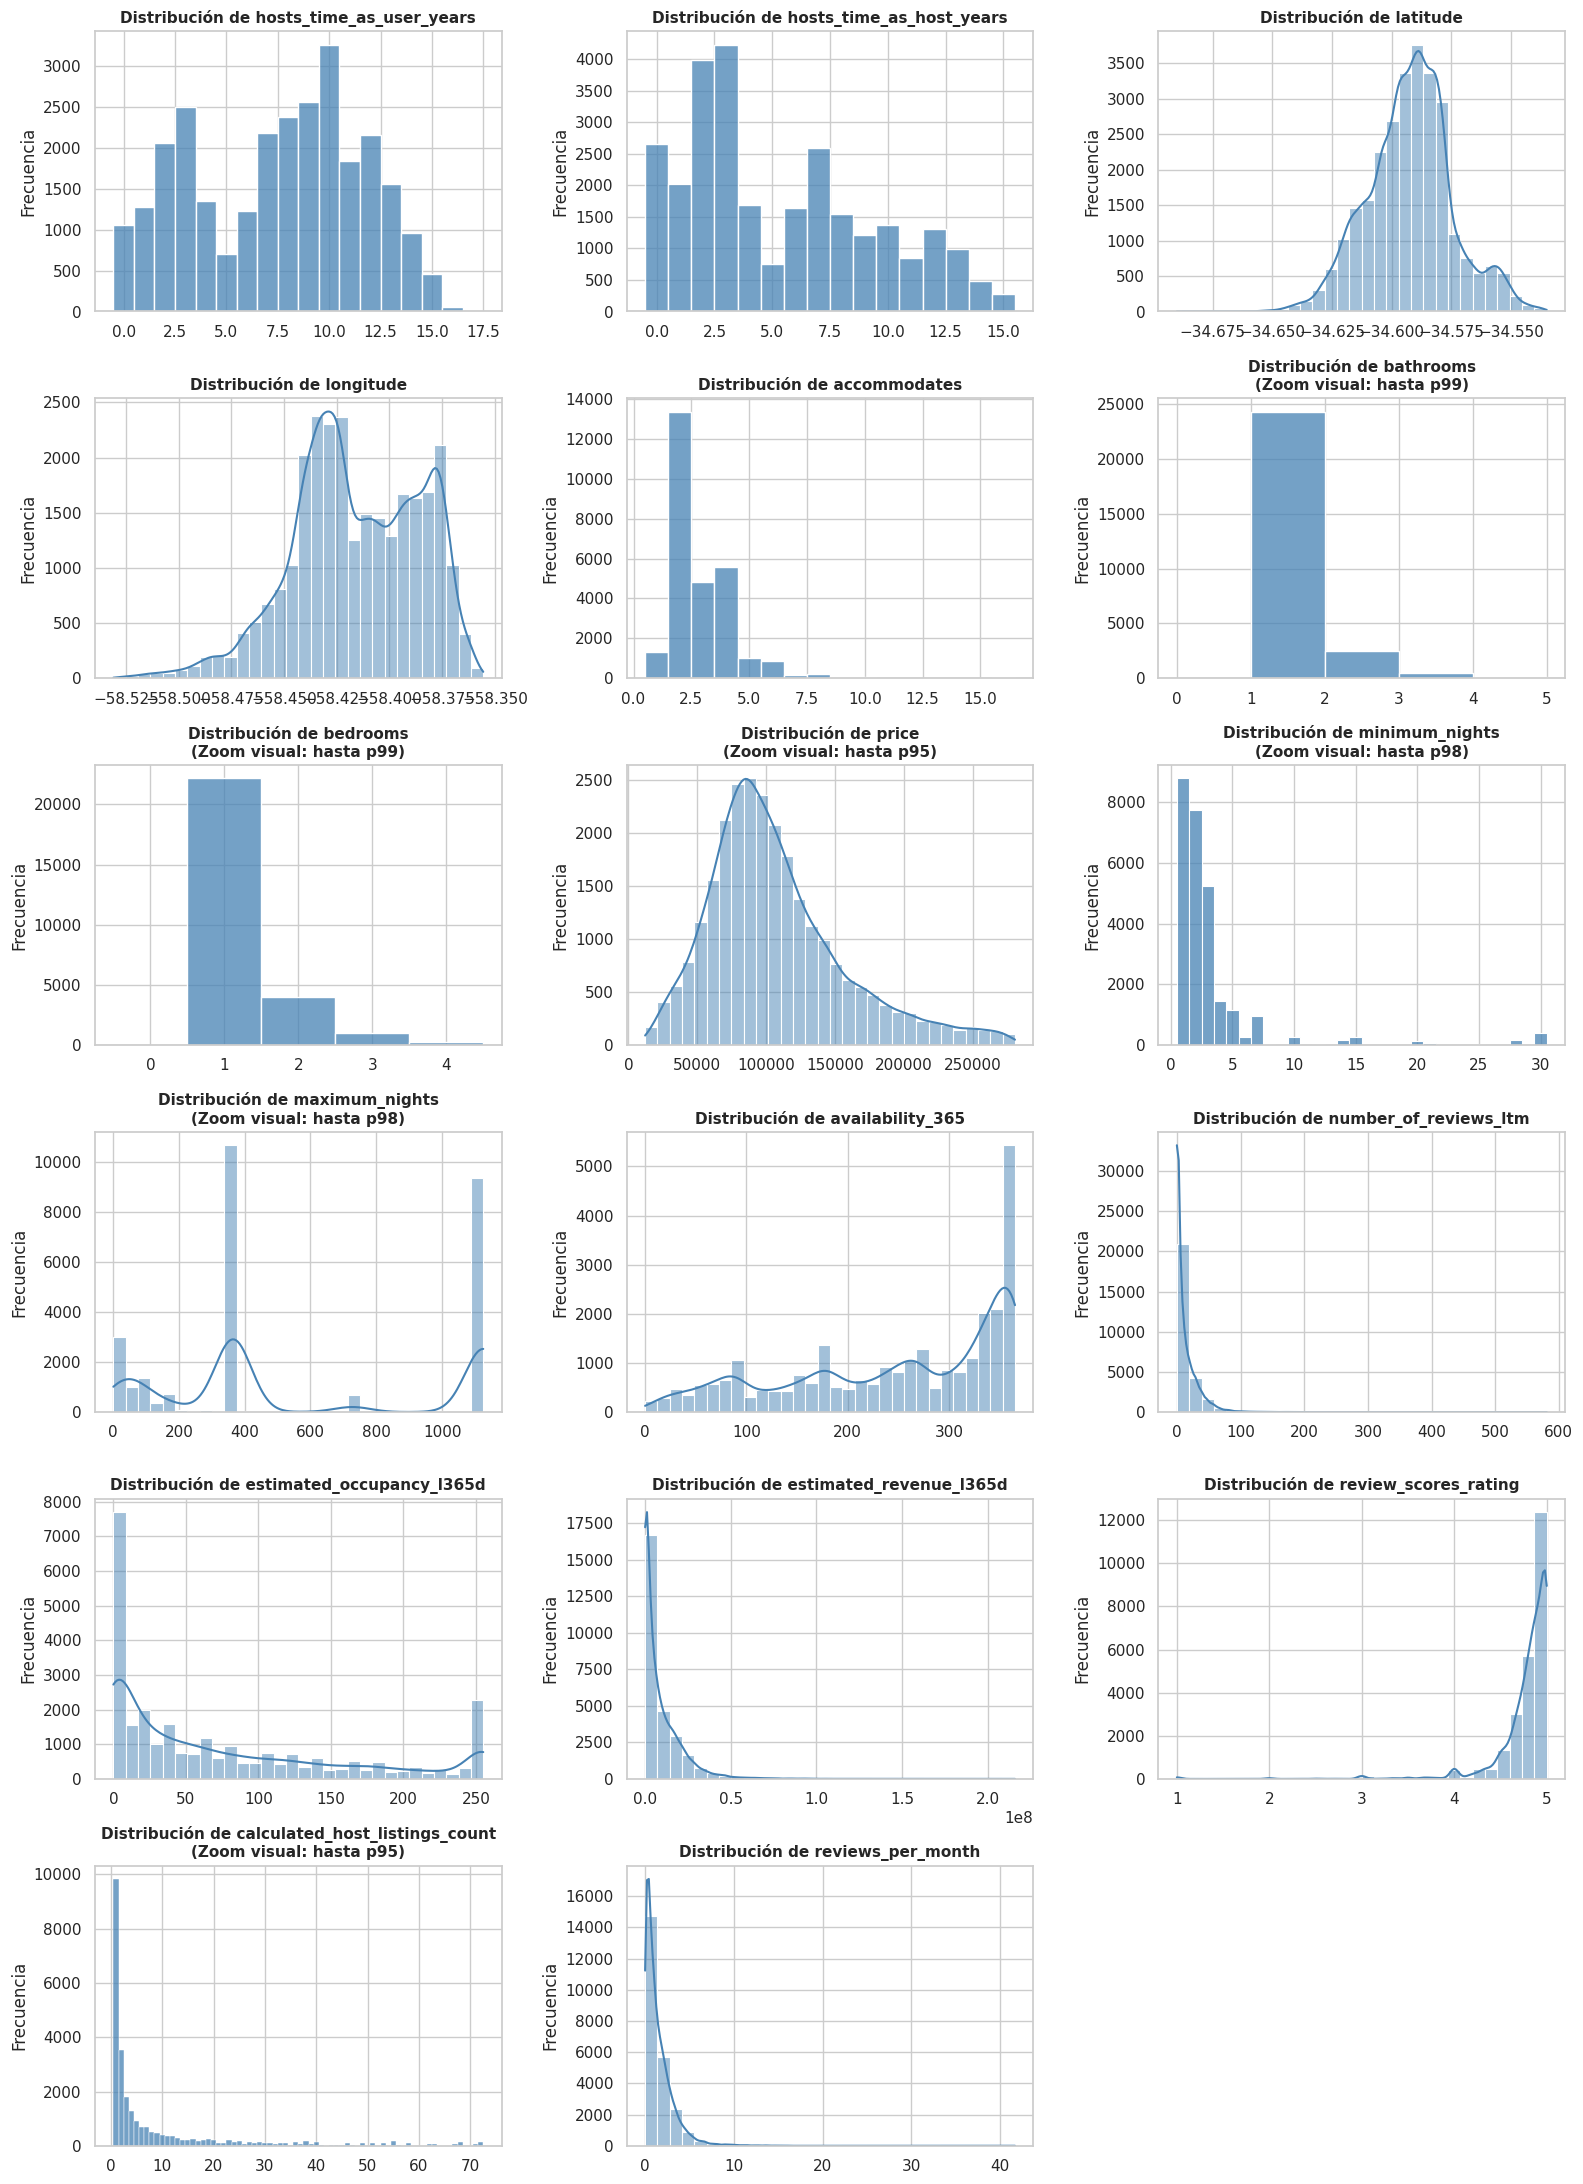

In [52]:
variables_numericas = [
    'hosts_time_as_user_years', 'hosts_time_as_host_years', 'latitude', 'longitude', 
    'accommodates', 'bathrooms', 'bedrooms', 'price', 'minimum_nights', 
    'maximum_nights', 'availability_365', 'number_of_reviews_ltm', 
    'estimated_occupancy_l365d', 'estimated_revenue_l365d', 
    'review_scores_rating', 'calculated_host_listings_count', 'reviews_per_month'
]

variables_discretas = [
    'hosts_time_as_user_years', 'hosts_time_as_host_years', 'accommodates', 
    'bathrooms', 'bedrooms', 'minimum_nights', 'calculated_host_listings_count'
]

variables_con_zoom = {
    'price': 0.95,
    'minimum_nights': 0.98,
    'maximum_nights': 0.98,
    'bathrooms': 0.99,
    'bedrooms': 0.99,
    'calculated_host_listings_count': 0.95
}

# Creamos una serie local para el precio (si es texto) sin modificar df_copia
if df_copia['price'].dtype == 'object':
    s_price = df_copia['price'].replace(r'[\$,]', '', regex=True).astype(float)
else:
    s_price = df_copia['price']

fig, axes = plt.subplots(nrows=6, ncols=3, figsize=(16, 22))
axes = axes.flatten()

for i, col in enumerate(variables_numericas):
    if col in df_copia.columns:
        # Usamos la serie local s_price si la columna es 'price', evitando mutar df_copia
        if col == 'price':
            datos = s_price.dropna()
        else:
            datos = df_copia[col].dropna()
            
        titulo = f'Distribución de {col}'
        
        # Aplicamos el zoom visual (solo afecta al gráfico, no al DataFrame)
        if col in variables_con_zoom:
            percentil = variables_con_zoom[col]
            datos = datos[datos <= datos.quantile(percentil)]
            titulo += f'\n(Zoom visual: hasta p{int(percentil*100)})'
            
        # Lógica de graficado: Discreta vs Continua
        if col in variables_discretas:
            sns.histplot(datos, discrete=True, kde=False, ax=axes[i], color='steelblue')
        else:
            sns.histplot(datos, bins=30, kde=True, ax=axes[i], color='steelblue')
        
        axes[i].set_title(titulo, fontweight='bold', fontsize=11)
        axes[i].set_xlabel('')
        axes[i].set_ylabel('Frecuencia')

# Eliminamos los ejes sobrantes
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

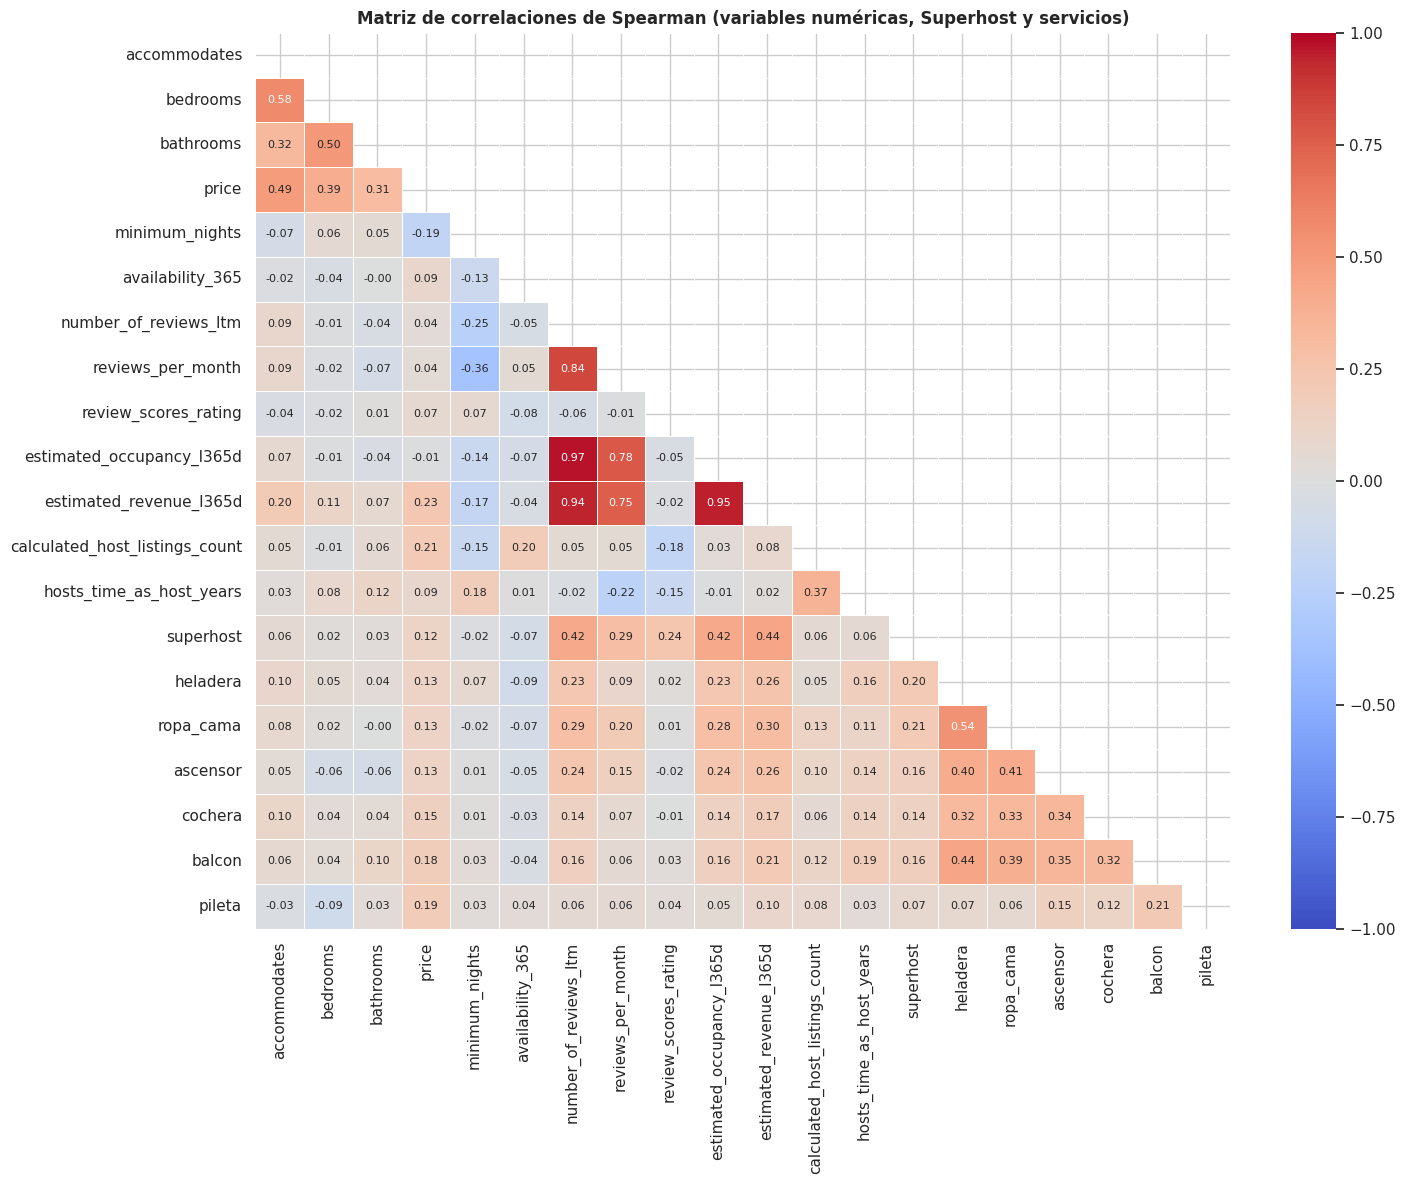

In [53]:
cols_num = ['accommodates', 'bedrooms', 'bathrooms', 'price', 'minimum_nights', 'availability_365',
            'number_of_reviews_ltm', 'reviews_per_month', 'review_scores_rating',
            'estimated_occupancy_l365d', 'estimated_revenue_l365d',
            'calculated_host_listings_count', 'hosts_time_as_host_years']

nombres_cortos = {"host_is_superhost": "superhost", "has_refrigerator": "heladera", "has_bed_linens": "ropa_cama",
                  "has_elevator": "ascensor", "has_parking": "cochera", "has_balcony_patio": "balcon", "has_pool": "pileta"}

datos_corr = df_copia[cols_num].copy()
for c, nombre in nombres_cortos.items():
    datos_corr[nombre] = df_copia[c].astype(float)      # 1 = sí, 0 = no

corr = datos_corr.corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(15, 12))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", annot_kws={"size": 8},
            cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=.5)
plt.title("Matriz de correlaciones de Spearman (variables numéricas, Superhost y servicios)", fontweight="bold")
plt.tight_layout(); plt.show()

#### 3.5. Correlaciones entre variables

Matriz de correlaciones de Spearman entre las variables numéricas, Superhost y los servicios del dataset limpio (Sección X del código). Se usa Spearman por las colas largas y los ceros inflados. Superhost y los servicios se codifican como 0/1 y se muestra solo la mitad inferior.

**Lectura de las correlaciones.**

* **Tamaño y precio:** capacidad, dormitorios y baños se correlacionan entre sí (0,32 a 0,58) y el precio sube con los tres, sobre todo con la capacidad (0,49).
* **Demanda:** las reseñas del último año, la ocupación y el ingreso estimados son casi equivalentes (0,94 a 0,97), consistente con que Inside Airbnb estime la ocupación a partir de las reseñas. El ingreso se asocia poco con el precio (0,23) y con la capacidad (0,20), y la ocupación casi nada (|ρ| ≤ 0,07): el ingreso sigue más a la demanda que a la tarifa o al tamaño.
* **Superhost:** se asocia con más demanda: reseñas, ocupación e ingreso (0,42 a 0,44), reseñas por mes (0,29) y mejor calificación (0,24). Casi no se asocia con el precio (0,12) ni con la capacidad (≤ 0,06). Esta relación es en parte mecánica, porque la insignia exige una actividad mínima y una calificación alta.
* **Servicios:** heladera, ropa de cama, ascensor, cochera y balcón/patio se asocian entre sí (0,32 a 0,54), mientras que la pileta es la más independiente (≤ 0,21). Cada servicio se asocia débilmente con el precio (0,13 a 0,19) y algo más con las reseñas, la ocupación y el ingreso (0,14 a 0,30; la pileta, ≤ 0,10).
* **Estadías mínimas largas:** `minimum_nights` se asocia negativamente con las reseñas por mes (−0,36), las del último año (−0,25), el precio (−0,19) y el ingreso (−0,17). Es plausible: con estadías largas hay menos huéspedes por año y, por lo tanto, menos reseñas.
* **Anfitriones con varias propiedades:** `calculated_host_listings_count` crece con la antigüedad del anfitrión (0,37) y se asocia con precios algo mayores (0,21), más disponibilidad (0,20) y calificaciones algo menores (−0,18).
* **Calificación:** `review_scores_rating` casi no se relaciona con el resto (|ρ| ≤ 0,18), salvo con Superhost (0,24). Es coherente con que casi toda la masa esté entre 4,5 y 5 (sección 3.2).

**Limitación.** Las correlaciones de Spearman miden asociación monótona, no causalidad, y la mayoría son de intensidad baja a moderada. Los valores muy altos entre reseñas, ocupación e ingreso son en parte mecánicos, por cómo se construyen las estimaciones.

# 4. Validación de hipótesis

### Hipótesis 1 (univariada): Baja ocupación media anual

#### Planteo

**Enunciado.** La ocupación anual estimada de los anuncios de Airbnb en CABA (`estimated_occupancy_l365d`) tiene una media inferior al 45 % del año, es decir, a 164,25 días ocupados de 365.

**Variable.** `estimated_occupancy_l365d`, cuantitativa discreta (días ocupados en los últimos 365). Es una estimación que Inside Airbnb calcula a partir de las reseñas: vale 0 para los anuncios sin reseñas en el último año y tiene un tope de 255 días (70 % del año).

**Justificación y valor generado.** En el alquiler temporario el ingreso depende de la tarifa y de las noches efectivamente ocupadas, por lo que la ocupación es uno de los dos determinantes de la rentabilidad. Se toma el 45 % del año como umbral de referencia (algo menos de la mitad); como esa elección es discrecional, más adelante se verifica cuánto depende de ella. Si la media resultara significativamente menor, el mercado estaría en general subutilizado y un inversor no debería proyectar ocupaciones altas, sino trabajar con escenarios conservadores.

#### Planteo del contraste

* **Hipótesis** (unilateral a izquierda, porque se afirma que la media es *inferior* al umbral):
  * $H_0: \mu \geq 164{,}25$ días ($\geq 45\,\%$ del año).
  * $H_1: \mu < 164{,}25$ días ($< 45\,\%$ del año).
  * donde $\mu$ es la media poblacional de días de ocupación anual estimada.
* **Nivel de significancia:** $\alpha = 0{,}05$.
* **Prueba:** test t para una media.

**Nota: ¿por qué no un test t apareado?** La dependencia entre anuncios del mismo anfitrión podría sugerir un test apareado, pero ese test resuelve otro problema: se usa cuando cada unidad se mide dos veces (por ejemplo, antes y después) y el contraste se hace sobre las diferencias. Acá cada anuncio aporta una sola medición que se compara con un valor fijo, y la dependencia es entre anuncios de un mismo anfitrión, no entre dos mediciones. Además no se pueden formar pares, porque los anfitriones tienen entre 1 y 208 anuncios. Esta dependencia por grupos se trata verificando el resultado con un solo anuncio por anfitrión (H1, H2, H3, H5 y H6); en H4 no es posible, y se discute como limitación

count    27580.00
mean        76.73
std         83.00
min          0.00
25%          6.00
50%         42.00
75%        126.00
max        255.00
Name: estimated_occupancy_l365d, dtype: float64


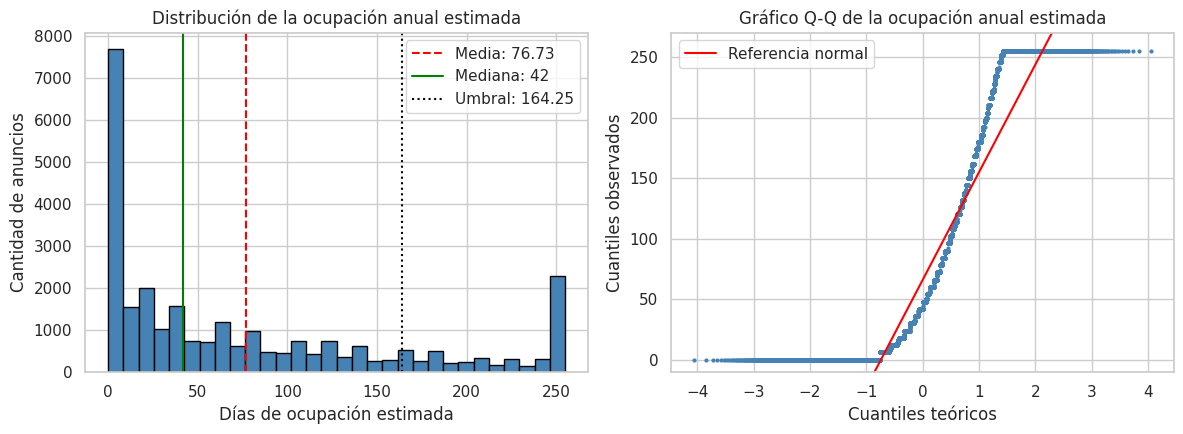

In [54]:
col = "estimated_occupancy_l365d"
umbral = 0.45 * 365          # 164,25 días
x = df_copia[col].dropna()

print(x.describe().round(2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# Histograma
ax[0].hist(x, bins=30, edgecolor="black", color="steelblue")
ax[0].axvline(x.mean(), color="red", linestyle="--", label=f"Media: {x.mean():.2f}")
ax[0].axvline(x.median(), color="green", label=f"Mediana: {x.median():.0f}")
ax[0].axvline(umbral, color="black", linestyle=":", label=f"Umbral: {umbral:.2f}")
ax[0].set_xlabel("Días de ocupación estimada")
ax[0].set_ylabel("Cantidad de anuncios")
ax[0].set_title("Distribución de la ocupación anual estimada")
ax[0].legend()

# QQ plot con recta de referencia por los cuartiles
(teoricos, ordenados), _ = stats.probplot(x, dist="norm")
z1, z3 = stats.norm.ppf([0.25, 0.75])
q1, q3 = np.percentile(x, [25, 75])
pend = (q3 - q1) / (z3 - z1)
orig = q1 - pend * z1
ax[1].scatter(teoricos, ordenados, s=4, color="steelblue")
ax[1].plot(teoricos, orig + pend * teoricos, color="red", label="Referencia normal")
ax[1].set_ylim(-10, 270)
ax[1].set_xlabel("Cuantiles teóricos")
ax[1].set_ylabel("Cuantiles observados")
ax[1].set_title("Gráfico Q-Q de la ocupación anual estimada")
ax[1].legend(loc="upper left")

plt.tight_layout()
plt.show()

#### Análisis gráfico

**Histograma.** La distribución es asimétrica a la derecha y presenta dos acumulaciones: una en los valores más bajos (el 22,3 % de los anuncios vale exactamente 0, porque no tiene reseñas en el último año) y otra en ~255 días, el tope del modelo de estimación de Inside Airbnb, donde queda el 7,8 % de los anuncios. Entre ambas la frecuencia decrece de forma progresiva, con algunas irregularidades. La media (76,7 días) supera a la mediana (42 días) por efecto de la cola derecha, y el 75 % de los anuncios tiene 126 días o menos. El umbral de 164,25 días queda lejos de ambas.

**Gráfico Q-Q.** Los puntos forman una S y se apartan de la recta de referencia, con dos tramos horizontales: uno en 0 días (cola inferior, 22,3 % de los datos) y otro en 255 días (cola superior, 7,8 %). Es el patrón de una variable inflada en cero y con un tope en el extremo superior, que no sigue una distribución normal.

En conjunto, la forma de la distribución no es normal, pero tanto la media como la mediana quedan muy por debajo del umbral, por lo que el gráfico anticipa el resultado del contraste.

In [55]:
# Submuestra de 5000: con n > 5000 el p-valor de Shapiro no es exacto
W, p = stats.shapiro(x.sample(5000, random_state=42))
print(f"Shapiro-Wilk (n = 5000): W = {W:.3f}, p = {p:.3g}")

Shapiro-Wilk (n = 5000): W = 0.833, p = 3.39e-58


#### Verificación de supuestos

El test t para una media supone que la media muestral es aproximadamente normal y que las observaciones son independientes. 

**Normalidad.** Se aplicó la prueba de Shapiro-Wilk sobre una muestra aleatoria de 5.000 observaciones (con más datos el p-valor no es exacto), con $H_0$: la variable sigue una distribución normal. El resultado ($W = 0{,}833$; $p < 0{,}001$) lleva a rechazar $H_0$, en línea con lo que mostraron el histograma y el gráfico Q-Q. Esto no invalida el test t, porque lo que debe ser aproximadamente normal es la *media muestral*, y con $n = 27.580$ el teorema central del límite lo asegura aunque la variable sea asimétrica y con tope. **El supuesto se cumple.**

**Independencia.** Los anuncios de un mismo anfitrión no son independientes entre sí. Para comprobar que esto no altera la conclusión, el contraste se repite con un solo anuncio por anfitrión.

In [56]:
# Test t para una media, unilateral a izquierda (H1: mu < umbral)
t, p = stats.ttest_1samp(x, popmean=umbral, alternative="less")
ic = stats.t.interval(0.95, df=len(x) - 1, loc=x.mean(), scale=stats.sem(x))
print(f"n = {len(x)} | media = {x.mean():.2f} ({x.mean()/365:.1%} del año) | t = {t:.2f} | p = {'< 0.001' if p < 0.001 else round(p, 4)}")
print(f"IC 95% de la media: ({ic[0]:.2f}, {ic[1]:.2f})")
print("Decisión:", "se rechaza H0" if p < 0.05 else "no se rechaza H0")

# Sensibilidad 1: solo anuncios activos (sin los ceros)
act = df_copia.loc[df_copia["number_of_reviews_ltm"] > 0, col]
t_a, p_a = stats.ttest_1samp(act, popmean=umbral, alternative="less")
print(f"Solo activos: n = {len(act)} | media = {act.mean():.2f} | t = {t_a:.1f} | p = {'< 0.001' if p_a < 0.001 else round(p_a, 4)}")

# Sensibilidad 2: dependencia por anfitrión 
por_host = df_copia.groupby("host_id").size()
multi = por_host[por_host > 1]
print(f"Anfitriones: {len(por_host)} | con más de un anuncio: {len(multi)} ({len(multi)/len(por_host):.1%}) "
      f"| anuncios de esos anfitriones: {multi.sum()/por_host.sum():.1%}")

un_por_host = df_copia.sample(frac=1, random_state=42).drop_duplicates("host_id")
x_h = un_por_host[col].dropna()
t_h, p_h = stats.ttest_1samp(x_h, popmean=umbral, alternative="less")
print(f"Un anuncio por anfitrión: n = {len(x_h)} | media = {x_h.mean():.2f} | t = {t_h:.1f} | p = {'< 0.001' if p_h < 0.001 else round(p_h, 4)}")

n = 27580 | media = 76.73 (21.0% del año) | t = -175.11 | p = < 0.001
IC 95% de la media: (75.75, 77.71)
Decisión: se rechaza H0
Solo activos: n = 21424 | media = 98.78 | t = -117.2 | p = < 0.001
Anfitriones: 13517 | con más de un anuncio: 3508 (26.0%) | anuncios de esos anfitriones: 63.7%
Un anuncio por anfitrión: n = 13517 | media = 74.52 | t = -127.1 | p = < 0.001


#### Conclusión

**Decisión.** Con $\alpha = 0{,}05$ se rechaza $H_0$ ($t = -175{,}11 < -1{,}645$; $p < 0{,}001$). **Se confirma la hipótesis:** la ocupación anual media estimada de los anuncios de Airbnb en CABA es inferior al 45 % del año.


* **La media es muy baja.** Es de 76,7 días, el 21,0 % del año, menos de la mitad del umbral (164,25 días).
* **El resultado es estable.** El intervalo de confianza del 95 % de la media es (75,75 ; 77,71) días. Todo el intervalo queda muy por debajo de 164,25, así que la conclusión no depende de la muestra y no se explica por azar. De hecho, $H_0$ se rechazaría con cualquier umbral mayor a ~78 días (≈ 21 % del año), por lo que la conclusión no depende de haber elegido el 45 %.
* **El anuncio típico rinde aún menos que el promedio.** La mediana (42 días) es menor que la media, porque los anuncios de ocupación alta (el 7,8 % está en el tope de 255 días) elevan la media.

**Verificaciones de robustez.** Se repitió el contraste para comprobar que el resultado no dependa de decisiones del análisis:

| Versión | Por qué se hizo | n | Media (días) | $t$ | Resultado |
|---|---|---|---|---|---|
| Todos los anuncios | Análisis principal | 27.580 | 76,7 | −175,1 | Se rechaza $H_0$ |
| Solo anuncios activos (con reseñas en el último año) | El 22,3 % de los anuncios tiene ocupación 0 y podría estar bajando el promedio | 21.424 | 98,8 | −117,2 | Se rechaza $H_0$ |
| Un anuncio por anfitrión | Los anuncios de un mismo anfitrión no son independientes | 13.517 | 74,5 | −127,1 | Se rechaza $H_0$ |

La conclusión es la misma en las tres versiones. Incluso sin los anuncios inactivos, la media (98,8 días, 27,1 % del año) queda muy por debajo del 45 %.

**Implicancia para el inversor.** No conviene proyectar ocupaciones cercanas al 45 % del año. Un escenario conservador puede basarse en la mediana (42 días) y uno optimista en la media de los anuncios activos (~99 días).

**Limitaciones**

* **La ocupación es una estimación.** Se calcula a partir de las reseñas con el modelo de Inside Airbnb y tiene un tope de ~255 días (70 % del año), por lo que la conclusión se refiere a la ocupación *estimada*, no a la observada. Aun si todos los anuncios en el tope hubieran estado ocupados los 365 días, la media subiría unos 9 días (≈ 85) y seguiría muy por debajo del umbral.
* **Dependencia entre anuncios.** Los 27.580 anuncios pertenecen a 13.517 anfitriones, y 3.508 de ellos (26,0 %) tienen más de un anuncio, de modo que las observaciones no son plenamente independientes y el p-valor tiende a ser más optimista de lo real. Por eso se hizo la verificación con un anuncio por anfitrión, que arroja el mismo resultado.

### Hipótesis 2 (bivariada): Confianza del Superhost

#### Planteo

**Enunciado.** Los anuncios de anfitriones con la insignia "Superhost" (`host_is_superhost`) tienen una mediana de ocupación anual estimada (`estimated_occupancy_l365d`) significativamente superior a la de los anuncios de anfitriones estándar. Se espera que la insignia funcione como un sello de confianza que facilita la reserva, pero ese mecanismo no puede medirse con estos datos: el contraste evalúa la parte medible de la afirmación, la diferencia de medianas de ocupación entre ambos grupos.

**Variables.**
* **Independiente (agrupación):** `host_is_superhost`, cualitativa nominal dicotómica. Es una característica del anfitrión: todos sus anuncios comparten el mismo valor.
* **Dependiente (respuesta):** `estimated_occupancy_l365d`, cuantitativa discreta (días ocupados en los últimos 365). Es una característica de cada anuncio.

**Justificación y valor generado.** Airbnb evalúa cada tres meses si el anfitrión cumple cuatro criterios: calificación promedio de al menos 4,8, tasa de respuesta de al menos 90 %, menos de 1 % de cancelaciones y al menos 10 estadías en el último año (o 100 noches en 3 reservas). Validar esta hipótesis permite cuantificar si ese esfuerzo operativo se asocia con mayor ocupación. Si los Superhosts ocupan significativamente más, podría justificarse que un inversor destine esfuerzo a la calidad del servicio para alcanzar la insignia, entendiéndolo como una inversión en marketing y no como un gasto. Como la insignia exige un mínimo de estadías, la relación puede ser en parte inversa (los anuncios más ocupados llegan con más facilidad a ser Superhost), por lo que el resultado se interpreta como asociación y no como efecto causal.

#### Planteo del contraste

* **Hipótesis** (unilateral a derecha, porque se afirma que los Superhosts tienen *más* ocupación):
  * $H_0: \theta_{Superhost} = \theta_{Estándar}$ (misma mediana de ocupación anual).
  * $H_1: \theta_{Superhost} > \theta_{Estándar}$.
  * donde $\theta$ es la mediana poblacional de ocupación anual de cada grupo.
* **Nivel de significancia:** $\alpha = 0{,}05$.
* **Comparación de medianas:** se compara la mediana y no la media porque la ocupación es muy asimétrica (inflada en 0 y con tope en 255 días, como se vio en H1).

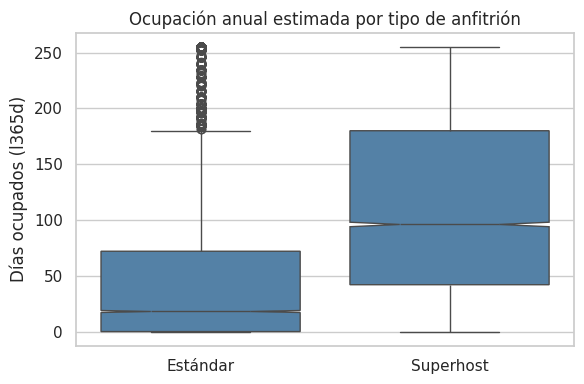

           count  median        mean
grupo                               
Estándar   16007    18.0   50.467421
Superhost  11573    96.0  113.054610
Spearman = 0.420, p-valor = 0


In [57]:
col = "estimated_occupancy_l365d"

d = df_copia[["host_is_superhost", col]].dropna().copy()
d["super_bin"] = d["host_is_superhost"].astype(int)   # True -> 1, False -> 0
d["grupo"] = d["super_bin"].map({1: "Superhost", 0: "Estándar"})

# Boxplot
plt.figure(figsize=(6, 4))
sns.boxplot(data=d, x="grupo", y=col, notch=True, order=["Estándar", "Superhost"], color="steelblue")
plt.title("Ocupación anual estimada por tipo de anfitrión")
plt.xlabel("")
plt.ylabel("Días ocupados (l365d)")
plt.tight_layout()
plt.show()

# Medianas por grupo
print(d.groupby("grupo")[col].agg(["count", "median", "mean"]))

# Spearman
rho, p = stats.spearmanr(d["super_bin"], d[col])
print(f"Spearman = {rho:.3f}, p-valor = {p:.4g}")

#### Análisis descriptivo y gráfico

| Grupo | n | Mediana | Media | Q1 | Q3 |
|---|---|---|---|---|---|
| Estándar | 16.007 | 18 | 50,5 | ≈ 0 | ≈ 73 |
| Superhost | 11.573 | 96 | 113,1 | ≈ 43 | ≈ 180 |

La mediana de los Superhost (96 días) es más de cinco veces la de los anuncios estándar (18 días). El gráfico de cajas (con *notches*) muestra una diferencia marcada entre ambos grupos:

* **Estándar:** distribución comprimida hacia valores bajos. El 75 % de los anuncios no supera los ~73 días ocupados.
* **Superhost:** caja más alta (mayor dispersión) y desplazada hacia arriba, con el 50 % central entre ~43 y ~180 días.
* **Muescas:** no se superponen, lo que sugiere que las medianas poblacionales difieren. La del grupo Estándar es más angosta por su mayor tamaño muestral y su menor rango intercuartílico.
* **Valores atípicos:** el grupo Estándar tiene una cola densa de atípicos hasta ~255 días, es decir, una ocupación alta es atípica *dentro de ese grupo*. En los Superhosts el bigote llega a ese mismo valor sin marcar atípicos. Ese tope no es un comportamiento real: coincide con el límite del modelo de Inside Airbnb (70 % × 365 ≈ 255 días), por lo que la variable, al ser una estimación, no llega al año completo.
* **Asociación:** Spearman $\rho = 0{,}420$ ($p < 0{,}001$) entre ser Superhost (codificado 0/1) y la ocupación: asociación positiva moderada.

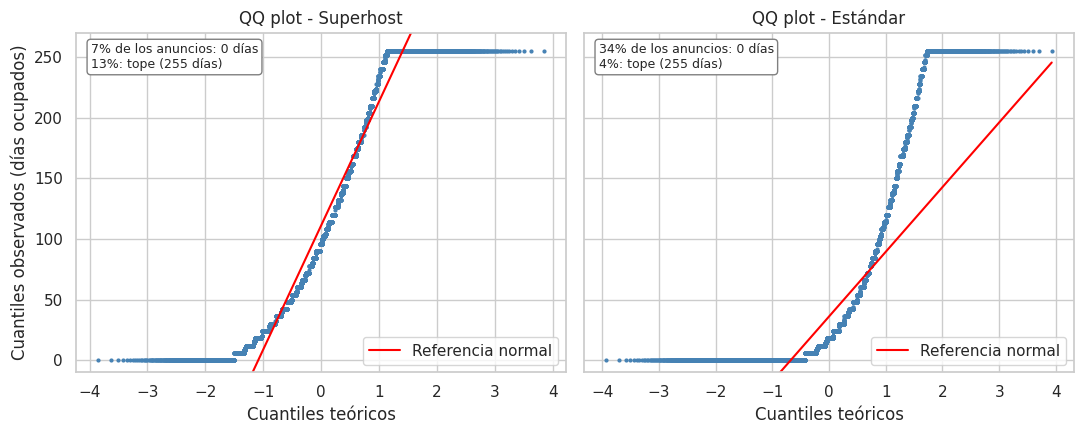

Shapiro Superhost: ShapiroResult(statistic=np.float64(0.9113491748481033), pvalue=np.float64(3.3240928160281535e-47))
Shapiro Estándar:  ShapiroResult(statistic=np.float64(0.7231760257674796), pvalue=np.float64(6.9126379636556444e-68))
Levene: LeveneResult(statistic=np.float64(1296.1621911176626), pvalue=np.float64(2.0475836780416316e-277))


In [58]:
col = "estimated_occupancy_l365d"
sup = df_copia.loc[df_copia["host_is_superhost"] == True, col].dropna()
est = df_copia.loc[df_copia["host_is_superhost"] == False, col].dropna()

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for a, (nombre, x) in zip(ax, [("Superhost", sup), ("Estándar", est)]):
    (teoricos, ordenados), _ = stats.probplot(x, dist="norm")

    # Recta de referencia por los cuartiles
    z1, z3 = stats.norm.ppf([0.25, 0.75])
    q1, q3 = np.percentile(x, [25, 75])
    pend = (q3 - q1) / (z3 - z1)
    orig = q1 - pend * z1

    a.scatter(teoricos, ordenados, s=4, color="steelblue")
    a.plot(teoricos, orig + pend * teoricos, color="red", lw=1.5, label="Referencia normal")
    a.set_ylim(-10, 270)
    a.set_title(f"QQ plot - {nombre}")
    a.set_xlabel("Cuantiles teóricos")
    a.legend(loc="lower right")

    # Peso de las dos pilas
    pct_cero = (x == 0).mean()
    pct_tope = (x == x.max()).mean()
    a.text(0.03, 0.97,
           f"{pct_cero:.0%} de los anuncios: 0 días\n{pct_tope:.0%}: tope ({x.max():.0f} días)",
           transform=a.transAxes, va="top", fontsize=9,
           bbox=dict(boxstyle="round", facecolor="white", edgecolor="gray"))

ax[0].set_ylabel("Cuantiles observados (días ocupados)")
plt.tight_layout()
plt.show()

# Shapiro-Wilk (submuestra de 5000: con n > 5000 el p-valor no es exacto)
print("Shapiro Superhost:", stats.shapiro(sup.sample(5000, random_state=42)))
print("Shapiro Estándar: ", stats.shapiro(est.sample(5000, random_state=42)))

# Homocedasticidad
print("Levene:", stats.levene(sup, est, center="median"))

#### Verificación de supuestos

* **Normalidad (Shapiro-Wilk sobre una submuestra aleatoria de 5.000 anuncios por grupo, y QQ plot):** Superhost $W = 0{,}911$ y Estándar $W = 0{,}723$, ambos con $p < 0{,}001$. Se rechaza la normalidad en los dos grupos. Los QQ plots lo confirman: los puntos se apartan de la recta de referencia y forman dos tramos horizontales, uno en 0 días (7 % de los Superhosts y 34 % de los Estándar) y otro en el tope de ~255 días del modelo de estimación (13 % y 4 %, respectivamente). La variable está inflada en cero y con un tope en el extremo superior.
* **Homocedasticidad (Levene, centrado en la mediana):** estadístico $= 1296{,}2$, $p < 0{,}001$. Se rechaza la igualdad de varianzas.
* **Independencia:** no se cumple. La insignia es una característica del anfitrión, por lo que todos los anuncios de un mismo anfitrión pertenecen al mismo grupo y comparten gestión. Los anuncios no son independientes y el test tiende a sobreestimar la significancia. Se verifica repitiendo el contraste con un solo anuncio por anfitrión.

**Elección del test:** la hipótesis se formuló sobre medianas, y con una distribución inflada en cero y con tope la media describe mal al anuncio típico; por eso se descarta el test t (que, con estas muestras, sí sería válido para comparar medias por el teorema central del límite). Mann-Whitney solo compara medianas si ambos grupos tienen la misma forma y dispersión, y acá las varianzas difieren (Levene). Se opta por la **prueba de la mediana**, que no supone normalidad ni varianzas iguales y contrasta directamente lo que afirma la hipótesis: las medianas.

In [59]:
def prueba_mediana(d):
    s = d["host_is_superhost"].astype(bool)
    sup, est = d.loc[s, col], d.loc[~s, col]
    chi2, p_bil, med_global, tabla = stats.median_test(sup, est)
    prop_sup, prop_est = tabla[0, 0] / len(sup), tabla[0, 1] / len(est)
    p_uni = p_bil / 2 if prop_sup > prop_est else 1 - p_bil / 2
    return {"n_sup": len(sup), "n_est": len(est), "med_sup": sup.median(), "med_est": est.median(),
            "% sobre mediana global (Sup)": f"{prop_sup:.1%}", "% (Est)": f"{prop_est:.1%}",
            "chi2": f"{chi2:.1f}", "p unilateral": "< 0.001" if p_uni < 0.001 else f"{p_uni:.4f}"}

un_por_host = df_copia.sample(frac=1, random_state=42).drop_duplicates("host_id")
versiones = {"Todos los anuncios": df_copia,
             "Un anuncio por anfitrión": un_por_host,
             "Solo anuncios activos": df_copia[df_copia["number_of_reviews_ltm"] > 0]}
print(pd.DataFrame({k: prueba_mediana(v) for k, v in versiones.items()}).T.to_string())

                          n_sup  n_est med_sup med_est % sobre mediana global (Sup) % (Est)    chi2 p unilateral
Todos los anuncios        11573  16007    96.0    18.0                        72.3%   33.6%  4023.0      < 0.001
Un anuncio por anfitrión   5159   8358   114.0    12.0                        80.6%   29.5%  3327.0      < 0.001
Solo anuncios activos     10799  10625   108.0    48.0                        62.1%   35.8%  1480.7      < 0.001


#### Conclusión

Con $\alpha = 0{,}05$ **se rechaza $H_0$** ($\chi^2 = 4.023{,}0$; $z \approx 63{,}4 > 1{,}645$; $p < 0{,}001$). La mediana de ocupación anual estimada de los Superhosts (96 días) supera en 78 días a la de los anfitriones estándar (18 días), y el 72,3 % de los Superhosts queda por encima de la mediana global (42 días) contra el 33,6 % de los Estándar.

**Se confirma la hipótesis en su parte medible:** el status de Superhost se asocia con una mediana de ocupación significativamente superior.

**Verificaciones de robustez.** Se repitió el contraste para comprobar que el resultado no dependa de decisiones del análisis:

| Versión | Por qué se hizo | n (Superhost / Estándar) | Mediana (días) | % sobre la mediana global | $\chi^2$ | Resultado |
|---|---|---|---|---|---|---|
| Todos los anuncios | Análisis principal | 11.573 / 16.007 | 96 vs 18 | 72,3 % vs 33,6 % | 4.023,0 | Se rechaza $H_0$ |
| Un anuncio por anfitrión | La insignia es del anfitrión y sus anuncios no son independientes | 5.159 / 8.358 | 114 vs 12 | 80,6 % vs 29,5 % | 3.327,0 | Se rechaza $H_0$ |
| Solo anuncios activos (con reseñas en el último año) | Los Superhosts casi no tienen ocupación 0 (7 % contra 34 % de los Estándar) | 10.799 / 10.625 | 108 vs 48 | 62,1 % vs 35,8 % | 1.480,7 | Se rechaza $H_0$ |

La conclusión es la misma en las tres versiones. Con un anuncio por anfitrión, que deja observaciones independientes entre sí, la diferencia se mantiene. Y sin los anuncios inactivos la brecha se reduce, pero los Superhosts siguen ocupando más del doble (108 contra 48 días).

No puede afirmarse que la insignia *genere* esa ventaja ni que se traduzca en mayor conversión de reservas, por las siguientes limitaciones:

* **La ocupación se estima a partir de las reseñas,** por lo que incluso entre anuncios activos la diferencia puede reflejar mayor volumen de reseñas y no necesariamente más reservas.
* **Relación en parte inversa.** Para obtener la insignia se exige un mínimo de estadías, de modo que los anuncios sin actividad casi nunca la tienen. Parte de la asociación es entonces mecánica.
* **Dependencia entre anuncios.** `host_is_superhost` es un atributo del anfitrión, y los anuncios de un mismo anfitrión comparten grupo, por lo que no son estrictamente independientes. Esto vuelve al p-valor más optimista de lo real, pero la verificación con un anuncio por anfitrión arroja el mismo resultado.
* **Es una asociación y no causalidad:** los Superhosts pueden diferir también en antigüedad, ubicación o precio. La hipótesis multivariada (H3) vuelve a medir el efecto del Superhost controlando por capacidad y equipamiento.

**Implicancia para el inversor:** alcanzar la insignia mediante una mejor atención al cliente es una estrategia promisoria, pero no un retorno garantizado.

### Hipótesis 3 (multivariada): Ingreso anual, Superhost y servicios a igual capacidad

### Planteo

__Enunciado__: Manteniendo constante la capacidad del alojamiento, el estatus de Superhost y los servicios que ofrece (heladera, ropa de cama, ascensor, cochera, balcón/patio y pileta) se asocian con un mayor ingreso anual estimado.

__Variables.__

* __Dependiente__: `estimated_revenue_l365d`, cuantitativa continua (se modela su logaritmo, por su fuerte asimetría).
* __Control (igual capacidad)__: `accommodates`, cuantitativa discreta, tratada como categórica (un valor por cada capacidad).
* __Independientes de interés__:
    * `host_is_superhost`: Superhost (factor de gestión), cualitativa dicotómica.
    * `has_refrigerator`, `has_bed_linens`, `has_elevator`, `has_parking`, `has_balcony_patio`, `has_pool`: equipamiento (heladera, ropa de cama, ascensor, cochera, balcón/patio y pileta), cualitativas dicotómicas.

__Justificación y valor generado:__ Permite ordenar los factores por su aporte al ingreso a igual capacidad, por ejemplo cuánto se asocia la insignia Superhost frente a una cochera o una pileta, y orienta dónde conviene invertir al anfitrión o a la agencia. Por ejemplo, entre dos departamentos para 4 personas, la hipótesis sostiene que factura más el gestionado por un Superhost y con ascensor, cochera y pileta, y el modelo mide cuánto aporta cada factor por separado. La capacidad es el principal determinante de la tarifa, por lo que se incluye como control para comparar alojamientos de igual tamaño. Superhost es una insignia de confianza que mejora la visibilidad y la conversión: H2 ya mostró que los Superhost tienen mayor ocupación, y acá se evalúa si eso se traduce en ingreso al descontar capacidad y equipamiento. Cochera y ascensor facilitan el uso en una ciudad de edificios en altura y poco estacionamiento; pileta y balcón/patio son diferenciales de gama alta; heladera y ropa de cama son servicios básicos que reducen la fricción del huésped. Los resultados se interpretan como asociaciones y no como efectos causales, y como el ingreso es una estimación (precio × ocupación estimada), cada efecto combina tarifa y demanda.

### Planteo del Contraste

Se utiliza regresión lineal múltiple porque permite estimar el efecto de cada factor manteniendo constantes los demás, incluida la capacidad, y contrastar cada efecto con un test t sobre su coeficiente. No se usan técnicas de reducción de dimensión (PCA, t-SNE, UMAP) ni clustering, porque interesa el efecto de cada factor por separado y no resumirlos ni agruparlos.

Se ajusta una regresión lineal múltiple:

$\ln(ingreso_i) = \beta_0 + \gamma_{capacidad_i} + \beta_2\,superhost_i + \beta_3\,heladera_i + \beta_4\,ropa_i + \beta_5\,ascensor_i + \beta_6\,cochera_i + \beta_7\,balcon_i + \beta_8\,pileta_i + \varepsilon_i$

donde $\gamma$ toma un valor distinto para cada capacidad (1, 2, 3, ... huéspedes). Así, cada coeficiente compara alojamientos con la misma capacidad.

Cada coeficiente se interpreta manteniendo constantes los demás, es decir, a igual capacidad y equipamiento. Cada afirmación se contrasta por separado, con un test t unilateral sobre su coeficiente:

* **Superhost:** $H_0: \beta_2 \leq 0$ vs. $H_1: \beta_2 > 0$
* **Heladera:** $H_0: \beta_3 \leq 0$ vs. $H_1: \beta_3 > 0$
* **Ropa de cama:** $H_0: \beta_4 \leq 0$ vs. $H_1: \beta_4 > 0$
* **Ascensor:** $H_0: \beta_5 \leq 0$ vs. $H_1: \beta_5 > 0$
* **Cochera:** $H_0: \beta_6 \leq 0$ vs. $H_1: \beta_6 > 0$
* **Balcón/patio:** $H_0: \beta_7 \leq 0$ vs. $H_1: \beta_7 > 0$
* **Pileta:** $H_0: \beta_8 \leq 0$ vs. $H_1: \beta_8 > 0$

Como contraste conjunto complementario, un test F sobre los 7 coeficientes: $H_0: \beta_2 = \beta_3 = \dots = \beta_8 = 0$ vs. $H_1$: al menos uno distinto de 0.

* **Base de análisis:** anuncios con ingreso > 0 (n = 21.424); los anuncios sin ingreso son inactivos y ln(0) no existe.
* **Nivel de significancia:** $\alpha = 0{,}05$.

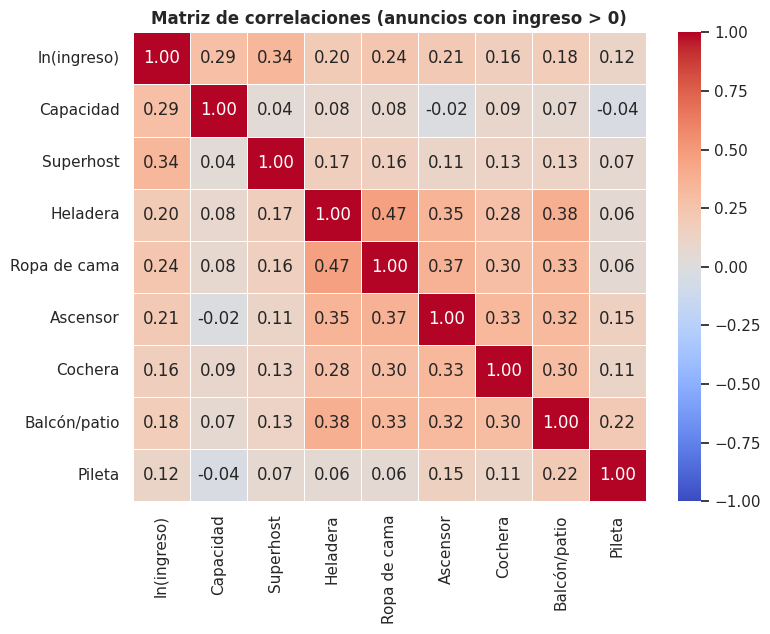

In [60]:
m = df_copia[df_copia["estimated_revenue_l365d"] > 0].copy()   # copia local
m["ln_ingreso"] = np.log(m["estimated_revenue_l365d"])
m["superhost"] = m["host_is_superhost"].astype(float)

nombres = {"ln_ingreso": "ln(ingreso)", "accommodates": "Capacidad", "superhost": "Superhost", "has_refrigerator": "Heladera",
           "has_bed_linens": "Ropa de cama", "has_elevator": "Ascensor", "has_parking": "Cochera",
           "has_balcony_patio": "Balcón/patio", "has_pool": "Pileta"}
corr = m[list(nombres)].corr().rename(index=nombres, columns=nombres)

plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=.5)
plt.title("Matriz de correlaciones (anuncios con ingreso > 0)", fontweight="bold")
plt.tight_layout(); plt.show()

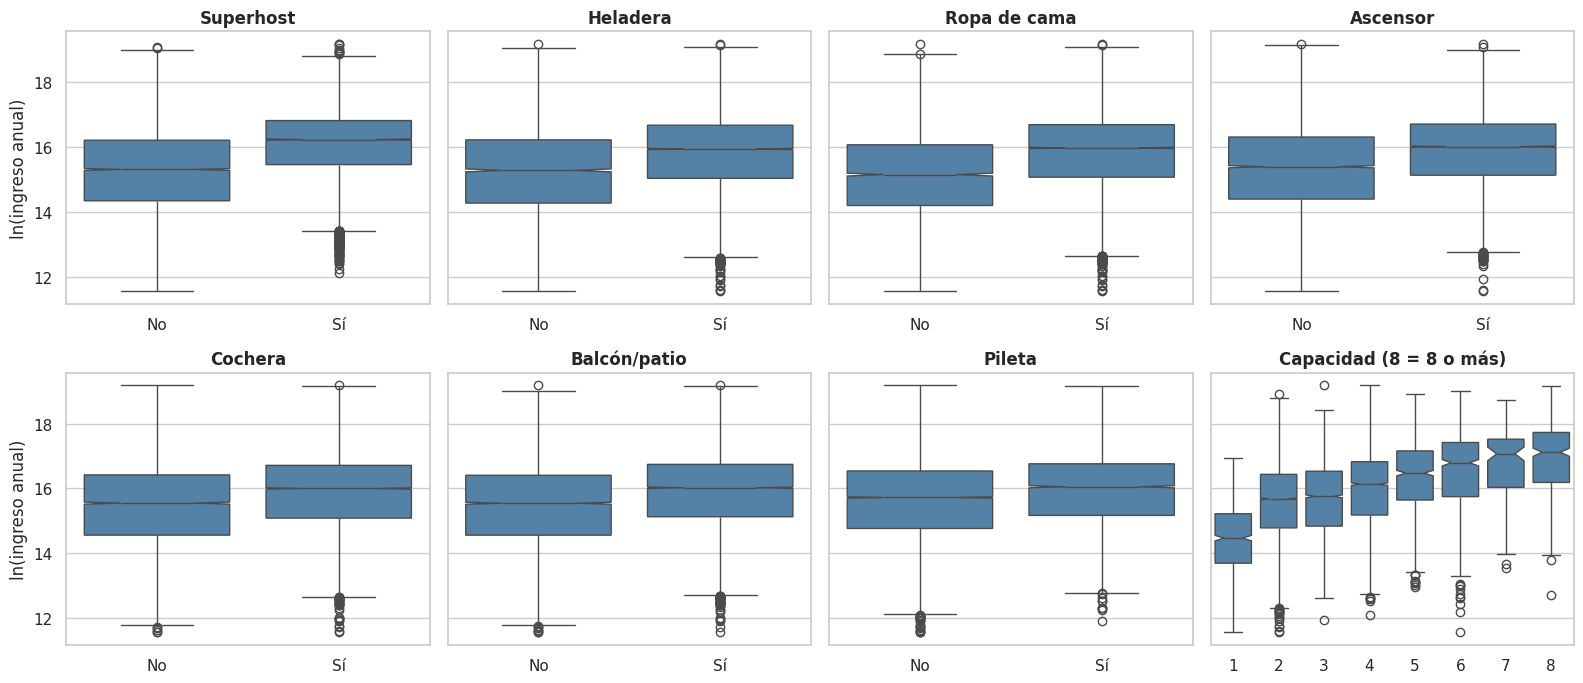

In [61]:
factores = {k: nombres[k] for k in ["superhost", "has_refrigerator", "has_bed_linens", "has_elevator", "has_parking", "has_balcony_patio", "has_pool"]}

fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey=True)
for ax, (col, nombre) in zip(axes.flat, factores.items()):
    sns.boxplot(data=m, x=col, y="ln_ingreso", notch=True, color="steelblue", ax=ax)
    ax.set_title(nombre, fontweight="bold"); ax.set_xlabel(""); ax.set_xticks([0, 1]); ax.set_xticklabels(["No", "Sí"])

sns.boxplot(x=m["accommodates"].clip(upper=8), y=m["ln_ingreso"], notch=True, color="steelblue", ax=axes[1, 3])
axes[1, 3].set_title("Capacidad (8 = 8 o más)", fontweight="bold"); axes[1, 3].set_xlabel("")

for ax in axes[:, 0]:
    ax.set_ylabel("ln(ingreso anual)")
for ax in axes.flat[1:]:
    if ax not in axes[:, 0]:
        ax.set_ylabel("")
plt.tight_layout(); plt.show()

**Análisis gráfico.** Se muestran las correlaciones entre ln(ingreso) y las variables del modelo, y la distribución de ln(ingreso) según cada factor.

* **Correlaciones con ln(ingreso):** todas son positivas, de intensidad baja a moderada. La más alta es la de Superhost (r = 0,34), seguida por la capacidad (0,29) y por las comodidades: ropa de cama (0,24), ascensor (0,21), heladera (0,20), balcón/patio (0,18), cochera (0,16) y pileta (0,12). Ningún factor por sí solo explica más del 12 % de la variabilidad del ingreso (0,34² ≈ 0,12), por lo que se espera un ajuste conjunto moderado.
* **Correlaciones entre predictoras:** la capacidad casi no se relaciona con las demás (|r| ≤ 0,09) y Superhost tampoco con las comodidades (0,07 a 0,17). Entre las comodidades las asociaciones son moderadas, con un máximo de 0,47 entre heladera y ropa de cama; la pileta es la más independiente. Ningún par se acerca a 0,7, por lo que no se anticipa multicolinealidad grave (se confirma luego con el VIF).
* **Boxplots por factor:** en los siete factores, la mediana de ln(ingreso) es mayor en el grupo "Sí" que en el "No". La diferencia es mayor en Superhost (≈ 0,9 en ln, es decir, una mediana de ingreso unas 2,5 veces mayor) y en ropa de cama, y menor en pileta, cochera y balcón/patio. Las cajas se solapan bastante, lo que indica mucha dispersión no explicada por estas variables.
* **Capacidad:** el ingreso crece con la capacidad, pero no de forma lineal: el salto más marcado es de 1 a 2 huéspedes, y entre 2 y 3 casi no cambia.

**Lectura.** La exploración es consistente con H3: los alojamientos con Superhost, con más comodidades y con mayor capacidad tienden a ingresar más. Son asociaciones bivariadas: la regresión múltiple permite separar el aporte de cada factor manteniendo los demás constantes.

n = 21,424 | R² = 0.258 | R² ajustado = 0.257


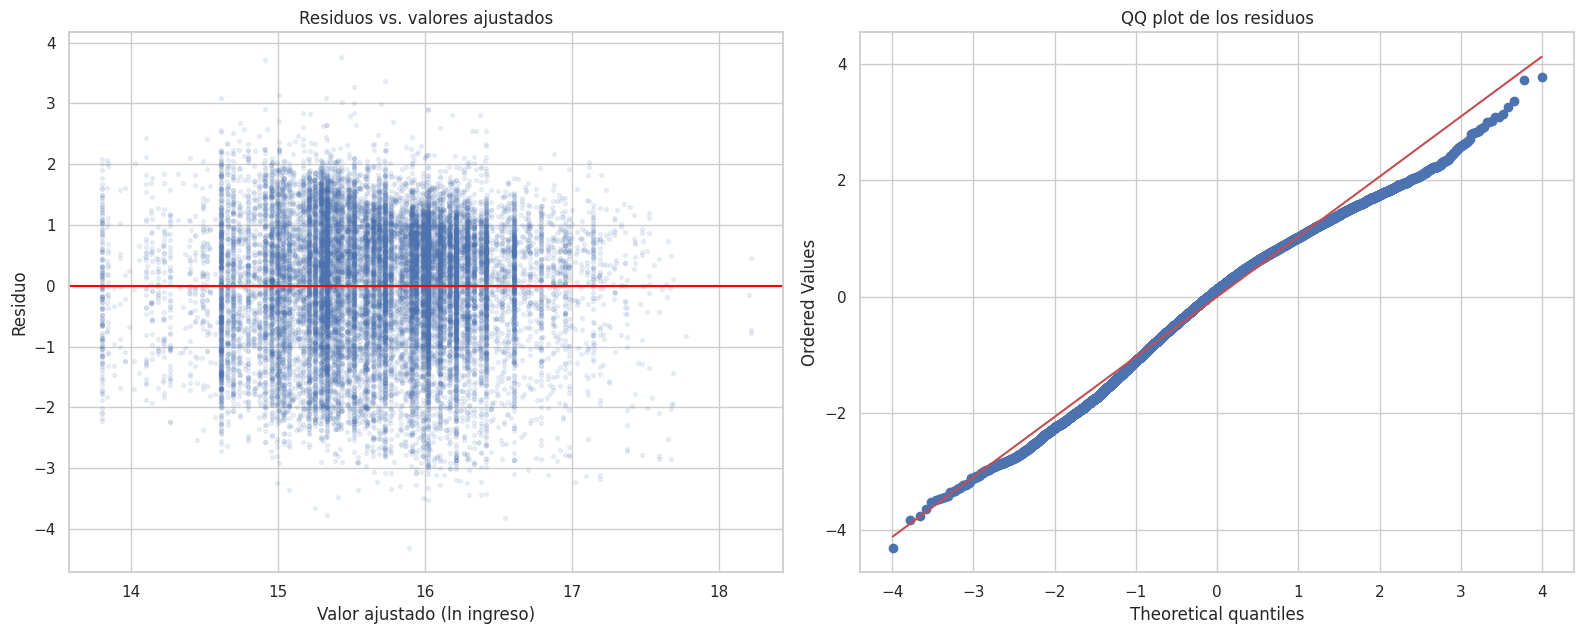

Breusch-Pagan: LM = 385.8, p = 3.50e-68
Shapiro-Wilk (5.000): W = 0.986, p = 3.90e-22
Durbin-Watson: 1.75 | ordenado por host_id: 1.57
superhost    1.05
heladera     1.45
ropa_cama    1.43
ascensor     1.35
cochera      1.23
balcon       1.33
pileta       1.08
dtype: float64


In [62]:
# Nombres cortos de los factores (columna original -> nombre en el modelo)
factores = {"host_is_superhost": "superhost", "has_refrigerator": "heladera", "has_bed_linens": "ropa_cama",
            "has_elevator": "ascensor", "has_parking": "cochera", "has_balcony_patio": "balcon", "has_pool": "pileta"}

# Base: anuncios con ingreso > 0
h3 = df_copia[df_copia["estimated_revenue_l365d"] > 0].copy()
h3["ln_ingreso"] = np.log(h3["estimated_revenue_l365d"])
for c, nombre in factores.items():
    h3[nombre] = h3[c].astype(int)          # 1 = tiene, 0 = no tiene

# Modelo: ln(ingreso) ~ capacidad (por categorías) + 7 factores
formula = "ln_ingreso ~ C(accommodates) + " + " + ".join(factores.values())
m = smf.ols(formula, data=h3).fit()
resid, ajust = m.resid, m.fittedvalues
print(f"n = {int(m.nobs):,} | R² = {m.rsquared:.3f} | R² ajustado = {m.rsquared_adj:.3f}")

# --- Gráficos: linealidad, homocedasticidad y normalidad ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

axes[0].scatter(ajust, resid, alpha=0.1, s=8)
axes[0].axhline(0, color="red")
axes[0].set(title="Residuos vs. valores ajustados", xlabel="Valor ajustado (ln ingreso)", ylabel="Residuo")

stats.probplot(resid, dist="norm", plot=axes[1])
axes[1].set_title("QQ plot de los residuos")
plt.tight_layout()
plt.show()

# --- Tests ---
bp = het_breuschpagan(resid, m.model.exog)                                   # homocedasticidad
sh = stats.shapiro(resid.sample(5000, random_state=42))                      # normalidad
dw_orig = durbin_watson(resid)                                               # independencia
dw_host = durbin_watson(h3.assign(resid=resid).sort_values("host_id")["resid"])

print(f"Breusch-Pagan: LM = {bp[0]:.1f}, p = {bp[1]:.2e}")
print(f"Shapiro-Wilk (5.000): W = {sh.statistic:.3f}, p = {sh.pvalue:.2e}")
print(f"Durbin-Watson: {dw_orig:.2f} | ordenado por host_id: {dw_host:.2f}")

# --- Multicolinealidad: VIF de los 7 factores ---
X = m.model.exog
vif = pd.Series([variance_inflation_factor(X, i) for i in range(X.shape[1])], index=m.model.exog_names)
print(vif[list(factores.values())].round(2))

**Resultados.** El modelo explica el 25,8 % de la variabilidad del logaritmo del ingreso ($R^2$ ajustado = 0,257).

* **Linealidad:** se cumple en lo esencial. Los residuos se distribuyen alrededor de 0 sin una curvatura marcada respecto de los valores ajustados.
* **Independencia:** no se cumple. Durbin-Watson vale 1,75 con el orden original y 1,57 al ordenar por `host_id`, ambos menores que 2, lo que indica que los errores de anuncios de un mismo anfitrión están correlacionados (correlación ≈ 0,2).
* **Homocedasticidad:** no se cumple. Breusch-Pagan rechaza ($p < 0{,}001$) y en el gráfico la dispersión de los residuos no es pareja: es menor en los valores ajustados más altos.
* **Normalidad:** se cumple solo de forma aproximada. Shapiro-Wilk rechaza ($W = 0{,}986$, $p < 0{,}001$), pero $W$ está muy cerca de 1 y el QQ plot sigue la recta en el centro, apartándose en los extremos, sobre todo en la cola derecha, que es más corta que la de una normal.
* **Multicolinealidad:** se cumple. Los VIF de los siete factores van de 1,05 a 1,45, muy por debajo de 5.

**Conclusión.** Se cumplen la linealidad y la ausencia de multicolinealidad. No se cumplen la independencia ni la homocedasticidad, y la normalidad solo aproximadamente. Esto no sesga los coeficientes estimados, pero sí puede volver poco precisos sus errores estándar y p-valores. Con 21.424 anuncios la falta de normalidad no es crítica, y la dependencia entre anuncios de un mismo anfitrión se verifica repitiendo la regresión con un solo anuncio por anfitrión.

In [63]:
un_por_host = h3.sample(frac=1, random_state=42).drop_duplicates("host_id")
versiones = {"Todos los anuncios": h3, "Un anuncio por anfitrión": un_por_host}

filas = []
for titulo, d in versiones.items():
    m = smf.ols(formula, data=d).fit()
    ic = m.conf_int()
    for v in factores.values():
        b, p2 = m.params[v], m.pvalues[v]
        p_uni = p2 / 2 if b > 0 else 1 - p2 / 2      # H1: coeficiente > 0
        filas.append({"versión": titulo, "factor": v, "n": int(m.nobs),
                      "coef": b, "efecto %": (np.exp(b) - 1) * 100,
                      "EE": m.bse[v], "t": m.tvalues[v], "p unilateral": p_uni,
                      "IC_inf": ic.loc[v, 0], "IC_sup": ic.loc[v, 1]})
    # F conjunto: ¿los 7 factores a la vez aportan algo, a igual capacidad?
    f = m.f_test(", ".join(f"{v} = 0" for v in factores.values()))
    print(f"{titulo}: F({int(f.df_num)}; {int(f.df_denom):,}) = {float(np.squeeze(f.fvalue)):.1f}, "
          f"p = {float(np.squeeze(f.pvalue)):.2e} | R² ajustado = {m.rsquared_adj:.3f}")

res = pd.DataFrame(filas).set_index(["versión", "factor"])
res.round({"coef": 4, "efecto %": 1, "EE": 4, "t": 2, "p unilateral": 4, "IC_inf": 4, "IC_sup": 4})

Todos los anuncios: F(7; 21,401) = 623.0, p = 0.00e+00 | R² ajustado = 0.257
Un anuncio por anfitrión: F(7; 10,628) = 462.7, p = 0.00e+00 | R² ajustado = 0.309


n    coef  efecto %      EE      t  \
versión                  factor                                              
Todos los anuncios       superhost  21424  0.6920      99.8  0.0145  47.61   
                         heladera   21424  0.0442       4.5  0.0209   2.11   
                         ropa_cama  21424  0.3000      35.0  0.0209  14.36   
                         ascensor   21424  0.2556      29.1  0.0173  14.74   
                         cochera    21424  0.0363       3.7  0.0160   2.27   
                         balcon     21424  0.0806       8.4  0.0165   4.88   
                         pileta     21424  0.1855      20.4  0.0164  11.29   
Un anuncio por anfitrión superhost  10651  0.9193     150.8  0.0196  46.90   
                         heladera   10651  0.0820       8.5  0.0285   2.88   
                         ropa_cama  10651  0.2019      22.4  0.0269   7.50   
                         ascensor   10651  0.1879      20.7  0.0228   8.25   
                         cochera    10651  0.0437       4.5  0.0216   2.02   
                         balcon     10651  0.0580       6.0  0.0220   2.64   
                         pileta     10651  0.1772      19.4  0.0229   7.75   

                                    p unilateral  IC_inf  IC_sup  
versión                  factor                                   
Todos los anuncios       superhost        0.0000  0.6635  0.7204  
                         heladera         0.0173  0.0032  0.0853  
                         ropa_cama        0.0000  0.2590  0.3409  
                         ascensor         0.0000  0.2216  0.2896  
                         cochera          0.0116  0.0050  0.0677  
                         balcon           0.0000  0.0483  0.1130  
                         pileta           0.0000  0.1533  0.2177  
Un anuncio por anfitrión superhost        0.0000  0.8809  0.9577  
                         heladera         0.0020  0.0262  0.1379  
                         ropa_cama        0.0000  0.1492  0.2547  
                         ascensor         0.0000  0.1433  0.2325  
                         cochera          0.0215  0.0014  0.0860  
                         balcon           0.0041  0.0150  0.1011  
                         pileta           0.0000  0.1324  0.2221

**Resultados y decisión.**

Se ajustó la regresión lineal múltiple planteada, con `ln(ingreso anual estimado)` como respuesta, la capacidad (`accommodates`) como control categórico y los siete factores como variables binarias. Para cada factor se contrastó H0: βⱼ ≤ 0 contra H1: βⱼ > 0 (j = 2, …, 8) con el test t unilateral, y para el conjunto se usó el test F. Como en las demás hipótesis, el ajuste se hizo con todos los anuncios (n = 21.424) y con un anuncio por anfitrión (n = 10.651), para verificar que el resultado no dependa de que un mismo anfitrión aparezca varias veces.

Test F conjunto (H0: los siete coeficientes son 0):
- Todos los anuncios: F(7; 21.401) = 623,0, p ≈ 0 | R² ajustado = 0,257
- Un anuncio por anfitrión: F(7; 10.628) = 462,7, p ≈ 0 | R² ajustado = 0,309

| Factor | Efecto % (todos / uno por anfitrión) | p unilateral (todos / uno por anfitrión) | Decisión (α = 0,05) |
|---|---|---|---|
| Superhost | +99,8 % / +150,8 % | < 0,001 / < 0,001 | Se rechaza H0 |
| Ropa de cama | +35,0 % / +22,4 % | < 0,001 / < 0,001 | Se rechaza H0 |
| Ascensor | +29,1 % / +20,7 % | < 0,001 / < 0,001 | Se rechaza H0 |
| Pileta | +20,4 % / +19,4 % | < 0,001 / < 0,001 | Se rechaza H0 |
| Balcón/patio | +8,4 % / +6,0 % | < 0,001 / 0,004 | Se rechaza H0 |
| Heladera | +4,5 % / +8,5 % | 0,017 / 0,002 | Se rechaza H0 |
| Cochera | +3,7 % / +4,5 % | 0,012 / 0,022 | Se rechaza H0 |

(Efecto % = (exp(β) − 1)·100, a igual capacidad y con los demás factores constantes.)

**Conclusión.** Se rechaza H0 en los siete factores, en ambas versiones, y el test F conjunto también la rechaza. Se confirma H3: a igual capacidad, los anuncios con Superhost, heladera, ropa de cama, ascensor, cochera, balcón/patio y pileta tienen un ingreso anual estimado mayor que los que no los tienen. El signo y la decisión no cambian al pasar de todos los anuncios a uno por anfitrión.

Por magnitud, el factor más asociado al ingreso es ser Superhost (aproximadamente +100 % a +151 %). Le siguen ropa de cama y ascensor (entre +21 % y +35 %) y pileta (alrededor de +20 %). Balcón/patio, heladera y cochera tienen asociaciones chicas (entre +4 % y +8,5 %).

**Limitaciones.**
- Es una asociación, no causalidad. Por ejemplo, ser Superhost refleja buena gestión y reseñas, y no necesariamente causa por sí solo más ingreso.
- Las magnitudes cambian entre versiones (por ejemplo, Superhost: +100 % contra +151 %), aunque no el signo ni la decisión. Por eso se informa el rango y no un valor único.
- La heterocedasticidad (Breusch-Pagan rechaza) no sesga los coeficientes, pero los errores estándar y los p-valores pueden ser algo imprecisos. Además, son siete contrastes simultáneos. Heladera y cochera son los que tienen la evidencia más débil: efecto chico, p entre 0,002 y 0,022 e IC inferior cercano a 0. Esas dos conclusiones deben leerse con más cautela que las otras cinco.

### Hipotesis 4 (univariada): Concentración de la oferta en multipropietarios

#### Planteo

**Enunciado.** *"Airbnb en Buenos Aires es un negocio de grandes jugadores: más del 60 % de la oferta la controlan agencias multipropiedad, no personas alquilando su propio hogar."* Se operacionaliza así: más del 60 % de los anuncios de Airbnb en CABA pertenece a anfitriones con más de una propiedad publicada.

**Variable.** `calculated_host_listings_count`, cuantitativa discreta (cantidad de anuncios que tiene el anfitrión en la ciudad). Se transforma en una variable dicotómica $X$: vale 1 si el anuncio pertenece a un anfitrión con 2 o más anuncios (multipropiedad) y 0 si no. Como $X$ solo toma los valores 0 y 1, su media es la proporción de la oferta en manos de multipropietarios.

**Justificación y valor generado.** Airbnb se presenta como una plataforma de personas que comparten su hogar, pero en los grandes destinos turísticos existe una oferta profesionalizada, con administradoras y propietarios de varias unidades. Medir qué parte de la oferta controlan importa para la regulación del alquiler temporario (que suele apuntar a esos actores), para el acceso a la vivienda y para un inversor, que competiría contra operadores profesionales y no contra particulares. Se toma el 60 % como umbral porque lo plantea el enunciado. Si la proporción resultara significativamente mayor, la oferta estaría concentrada en multipropietarios; si no, predominarían los particulares. Como "multipropiedad" no equivale a "agencia" (un particular con dos departamentos cuenta igual), más adelante se repite el contraste con criterios más estrictos (3, 5 y 10 o más anuncios).

#### Planteo del contraste

* **Hipótesis** (unilateral a derecha, porque se afirma que la proporción *supera* el umbral):
  * $H_0: p \leq 0{,}60$ (el 60 % o menos de los anuncios es de multipropietarios).
  * $H_1: p > 0{,}60$.
  * donde $p$ es la proporción poblacional de anuncios de anfitriones con 2 o más propiedades, es decir, la media de $X$.
* **Nivel de significancia:** $\alpha = 0{,}05$.
* **Prueba:** test t para una media sobre $X$, como en H1.

count    27580.00
mean        15.54
std         33.24
min          1.00
25%          1.00
50%          3.00
75%         12.00
max        208.00
Name: calculated_host_listings_count, dtype: float64


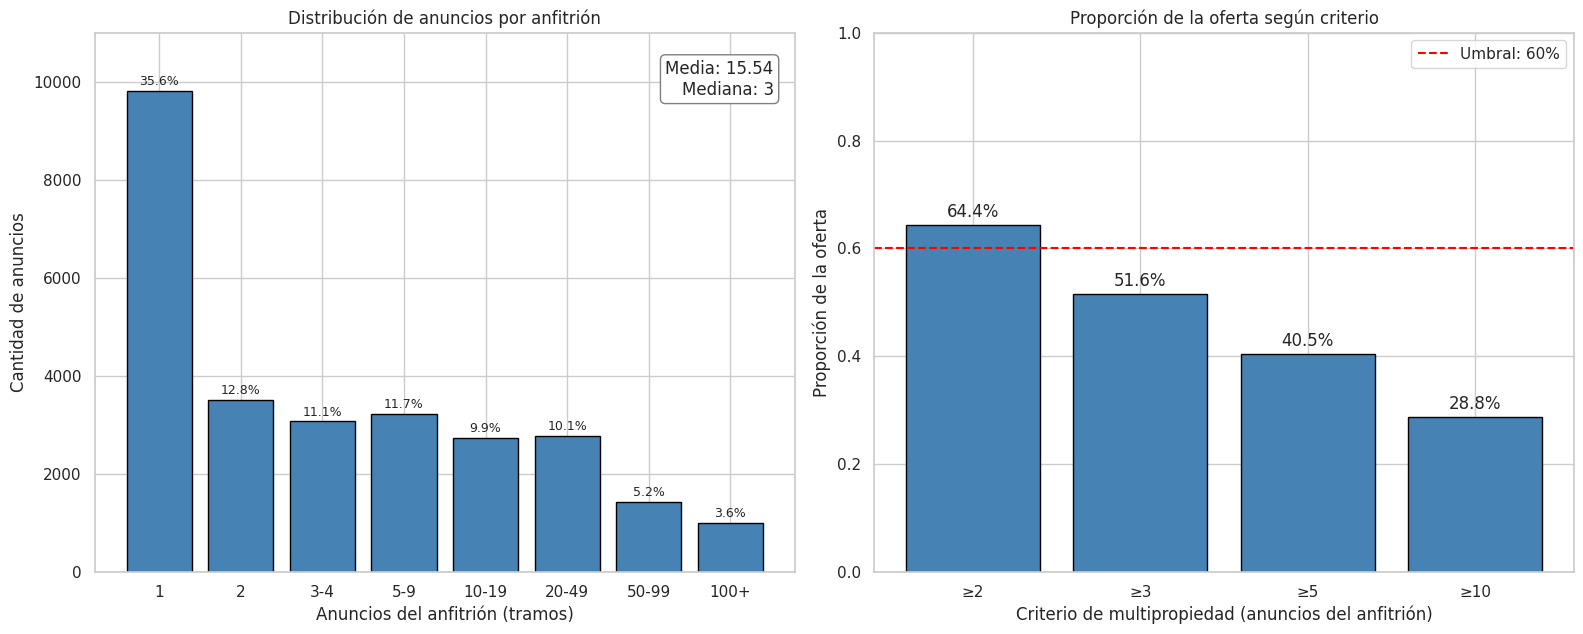

In [64]:
col = "calculated_host_listings_count"
k, p0 = 2, 0.60
x = df_copia[col]
criterios = [2, 3, 5, 10]
props = [(x >= c).mean() for c in criterios]

# Tramos: los cortes coinciden con los criterios ≥2, ≥3, ≥5 y ≥10
tramos = pd.cut(x, bins=[0, 1, 2, 4, 9, 19, 49, 99, np.inf],
                labels=["1", "2", "3-4", "5-9", "10-19", "20-49", "50-99", "100+"]).value_counts(sort=False)

print(x.describe().round(2))

fig, ax = plt.subplots(1, 2, figsize=(16, 6.5))

# Histograma por tramos
barras0 = ax[0].bar(tramos.index.astype(str), tramos.values, edgecolor="black", color="steelblue")
ax[0].bar_label(barras0, labels=[f"{v / len(x):.1%}" for v in tramos.values], padding=2, fontsize=9)
ax[0].set_ylim(0, tramos.max() * 1.12)
ax[0].text(0.97, 0.95, f"Media: {x.mean():.2f}\nMediana: {x.median():.0f}", transform=ax[0].transAxes,
           ha="right", va="top", bbox=dict(boxstyle="round", facecolor="white", edgecolor="gray"))
ax[0].set_xlabel("Anuncios del anfitrión (tramos)")
ax[0].set_ylabel("Cantidad de anuncios")
ax[0].set_title("Distribución de anuncios por anfitrión")

# Proporción de la oferta según criterio de multipropiedad
barras = ax[1].bar([f"≥{c}" for c in criterios], props, edgecolor="black", color="steelblue")
ax[1].bar_label(barras, labels=[f"{p:.1%}" for p in props], padding=3)
ax[1].axhline(p0, color="red", linestyle="--", label=f"Umbral: {p0:.0%}")
ax[1].set_ylim(0, 1)
ax[1].set_xlabel("Criterio de multipropiedad (anuncios del anfitrión)")
ax[1].set_ylabel("Proporción de la oferta")
ax[1].set_title("Proporción de la oferta según criterio")
ax[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

#### Análisis gráfico

**Histograma.** La distribución es fuertemente asimétrica a la derecha. El tramo más grande es el de anfitriones con un solo anuncio (35,6 % de la oferta) y las frecuencias bajan a medida que crece el tamaño del anfitrión, pero con una cola larga: el 28,8 % de los anuncios pertenece a anfitriones con 10 o más propiedades y el 3,6 % a anfitriones con 100 o más (el máximo es 208). Por eso la media (15,54) supera tanto a la mediana (3): cada anuncio hereda el conteo de su anfitrión, así que los anfitriones grandes pesan más. 

**Proporción según criterio.** Con el criterio literal del enunciado (≥ 2 anuncios), el 64,4 % de la oferta pertenece a multipropietarios, por encima del umbral del 60 %. La proporción baja a medida que se exige más propiedades: 51,6 % con ≥ 3, 40,5 % con ≥ 5 y 28,8 % con ≥ 10. Solo el criterio ≥ 2 supera el 60 %.

En conjunto, los gráficos anticipan que la hipótesis se cumple con el criterio literal, pero con un margen acotado (4,4 puntos sobre el umbral), y que la conclusión depende de cómo se defina "agencia": con definiciones más estrictas, la oferta controlada por grandes operadores es minoritaria. 

In [65]:
X = (df_copia["calculated_host_listings_count"] >= k).astype(int)   # 1 = multipropietario
n = len(X)

# Normalidad: X solo toma 0 y 1, la inferencia se apoya en el TCL (casos esperados bajo H0)
print(f"Valores de X: {sorted(X.unique().tolist())} | n = {n}")
print(f"Esperados bajo H0: multipropietarios = {n*p0:.0f} | resto = {n*(1-p0):.0f}  (mínimo habitual: 10)")


Valores de X: [0, 1] | n = 27580
Esperados bajo H0: multipropietarios = 16548 | resto = 11032  (mínimo habitual: 10)


#### Verificación de supuestos

El test t para una media supone que la media muestral es aproximadamente normal y que las observaciones son independientes. No se evalúa homocedasticidad, porque se compara contra un valor fijo y hay un único grupo.

**Normalidad.** El test t compara la media muestral con el valor del umbral y calcula el p-valor con una campana normal. Lo que tiene que ser normal no son los datos, sino la *distribución de la media muestral*, es decir, cómo variaría esa media si se sacaran muchas muestras distintas.

Acá la media se calcula sobre $X$, que vale 0 o 1. Por ejemplo, si 3 de 5 anuncios son de multipropietarios, la media de $X$ es 0,6. **La media de $X$ es entonces la proporción de multipropietarios.** Como $X$ solo toma dos valores, no puede ser normal, y aplicar Shapiro-Wilk o un gráfico Q-Q sobre ella no tiene sentido.

El teorema central del límite asegura que la media muestral se aproxima a una normal cuando la muestra es grande, pero con una variable de 0 y 1 "grande" significa que haya suficientes casos de cada tipo. Con 5 anuncios, por ejemplo, la proporción solo puede valer 0, 20, 40, 60, 80 o 100 %, y su distribución es una escalera y no una campana. La regla práctica es que, bajo $H_0$, se esperen al menos 10 casos de cada tipo.

Con $n = 27.580$ y $p_0 = 0{,}60$ se esperan $0{,}60 \times 27.580 = 16.548$ anuncios de multipropietarios y $0{,}40 \times 27.580 = 11.032$ del resto. Se usa el 60 % y no el 64,4 % observado porque el test razona suponiendo que $H_0$ es cierta. Ambos valores superan por mucho el mínimo de 10, por lo que la media muestral es aproximadamente normal. **El supuesto se cumple.**

**Independencia.** Este supuesto no se cumple, y ya se había visto en H3: los anuncios de un mismo anfitrión no son independientes porque comparten gestión, fotos y política de precios. Acá la dependencia es todavía más fuerte, porque `calculated_host_listings_count` es una característica del anfitrión y no del anuncio: todos los anuncios de un mismo anfitrión tienen el mismo valor de $X$. Un anfitrión con 100 anuncios es entonces una sola decisión contada 100 veces. El test t clásico, que la trata como 100 datos independientes, subestima el error estándar, y por eso su $t$ y su p-valor resultan exagerados.

**Cómo se trata.** En esta hipótesis no sirve repetir el test con un solo anuncio por anfitrión, como en H2: al ser $X$ igual para todos los anuncios de un anfitrión, esa submuestra mediría la proporción de *anfitriones* multipropietarios (27,3 %) y no la de *anuncios* (64,4 %), que es lo que plantea el enunciado. Por eso se aplica el test t de una media con todos los anuncios, y el resultado se interpreta con cautela: se pone el foco en la distancia entre la proporción observada y el umbral, no en la magnitud del $t$.

In [66]:
col = "calculated_host_listings_count"
pv = lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}"

def contraste(c):
    X = (df_copia[col] >= c).astype(int)
    n, ph = len(X), X.mean()
    ee = X.std(ddof=1) / np.sqrt(n)                # error estándar de una media
    t = (ph - p0) / ee
    p = stats.t.sf(t, n - 1)                       # unilateral a derecha, gl = n - 1
    lo, hi = stats.t.interval(0.95, df=n - 1, loc=ph, scale=ee)
    return {"criterio": f"≥{c}", "n": n, "p_hat": ph, "EE": ee, "t": t, "p": p, "IC_inf": lo, "IC_sup": hi}

res = pd.DataFrame([contraste(c) for c in [2, 3, 5, 10]]).set_index("criterio")

# Análisis principal: criterio ≥ 2
pr = res.loc["≥2"]
print(f"Anuncios: {pr['n']:.0f} | p̂ = {pr['p_hat']:.4f} ({pr['p_hat']:.1%}) | EE = {pr['EE']:.4f}")
print(f"t = {pr['t']:.2f} | p {pv(pr['p'])} | IC 95%: ({pr['IC_inf']:.4f}, {pr['IC_sup']:.4f})")
print("Decisión:", "se rechaza H0" if pr["p"] < 0.05 else "no se rechaza H0")

# Sensibilidad: otros criterios de multipropiedad
print(res[["p_hat", "t", "p"]].round(3))

# Unidad de análisis: anfitriones en lugar de anuncios
por_host = df_copia.drop_duplicates("host_id")[col]
print(f"Medido por anfitriones: {(por_host >= k).mean():.1%} tiene {k} o más anuncios")

Anuncios: 27580 | p̂ = 0.6435 (64.4%) | EE = 0.0029
t = 15.10 | p < 0.001 | IC 95%: (0.6379, 0.6492)
Decisión: se rechaza H0
          p_hat        t    p
criterio                     
≥2        0.644   15.099  0.0
≥3        0.516  -27.929  1.0
≥5        0.405  -66.126  1.0
≥10       0.288 -114.563  1.0
Medido por anfitriones: 27.3% tiene 2 o más anuncios


#### Conclusión del contraste

Se contrasta, con el t de una media, si la proporción de anuncios de multipropietarios (anfitriones con 2 o más anuncios) supera el 60 %.

* **Estimación:** $\hat{p} = 64{,}4\ \%$ sobre 27.580 anuncios, con error estándar de 0,0029.
* **Estadístico:** $t = 15{,}10$; p-valor unilateral < 0,001.
* **IC 95 %:** (63,8 %; 64,9 %).

**Decisión.** Como $p < \alpha = 0{,}05$, se rechaza $H_0$.

**Sensibilidad al criterio de multipropiedad.**

| Criterio | $\hat{p}$ | $t$ | Decisión |
|---|---|---|---|
| ≥ 2 anuncios | 64,4 % | 15,10 | se rechaza $H_0$ |
| ≥ 3 anuncios | 51,6 % | −27,93 | no se rechaza $H_0$ |
| ≥ 5 anuncios | 40,5 % | −66,13 | no se rechaza $H_0$ |
| ≥ 10 anuncios | 28,8 % | −114,56 | no se rechaza $H_0$ |

**Conclusión.** El enunciado se confirma con el criterio principal: el 64,4 % de los anuncios pertenece a anfitriones con al menos dos propiedades, y el intervalo de confianza queda por encima del 60 %. Sin embargo, el resultado depende de cómo se defina a un multipropietatio: con 3 o más anuncios la proporción baja a 51,6 %, y con 10 o más a 28,8 %, ambas por debajo del 60 %. Medido por anfitriones, solo el 27,3 % tiene 2 o más anuncios, pero ese grupo concentra el 64,4 % de la oferta.

**Cómo leer el resultado.** El test pregunta si la proporción real de anuncios de multipropietarios es mayor al 60 %. Un $t$ positivo y grande indica que la proporción observada está por encima del umbral, y uno negativo, como en los otros criterios, que está por debajo.

**Limitaciones.**

* Los anuncios de un mismo anfitrión no son independientes, por lo que el $t$ y el intervalo de confianza resultan más optimistas de lo real (el intervalo verdadero es más ancho). Conviene leer la conclusión por la distancia entre la proporción observada y el umbral (64,4 % contra 60 %), no por la magnitud del $t$.
* "Multipropietario" se definió como tener 2 o más anuncios, el mínimo posible. Con definiciones más exigentes de multipropietario, el enunciado no se sostiene.

### Hipotesis 5 (bivariada): Mas del doble de precio del alquiler

### Planteo

__Enunciado__: Alquilar un espacio entero cuesta, en promedio, más del doble que alquilar una habitación privada.

__Variables.__

* __Independiente__: `room_type`, cualitativa nominal. Se comparan solo dos categorías: `Entire home/apt` ("espacio entero") y `Private room` ("habitación privada"). Se excluyen `Shared room` y `Hotel room`.
* __Dependiente__: `price`, cuantitativa continua.

__Justificación y valor generado:__ El tipo de alojamiento (propiedad completa o habitación dentro de una vivienda) es uno de los factores que más se asocia al precio en el mercado de alquileres temporales. Esta hipótesis evalúa si esa brecha es tan grande que el precio medio de un espacio entero supera el doble del de una habitación privada. Para un anfitrión que decide cómo ofrecer su propiedad, o para la plataforma al definir precios de referencia, dimensionar esa brecha ayuda a valorar lo que aporta el espacio completo. La diferencia refleja privacidad, pero también mayor capacidad y equipamiento, por lo que se interpreta como asociación y no como efecto causal.

### Planteo del Contraste

* $H_0: \mu_{entero} \leq 2\,\mu_{privada}$
* $H_1: \mu_{entero} > 2\,\mu_{privada}$

* **Nivel de significancia:** $\alpha = 0{,}05$.

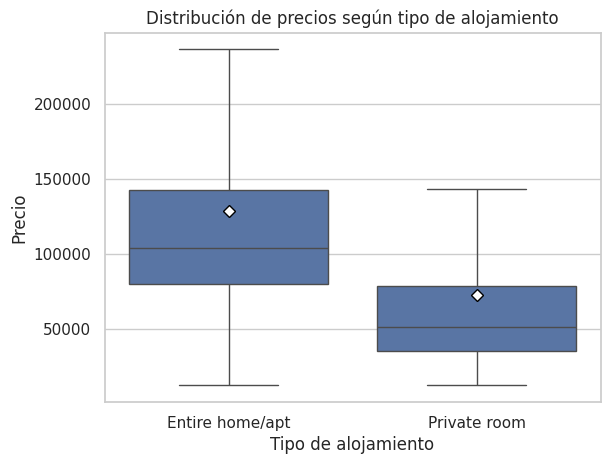

In [67]:
data_precios = df_copia[df_copia["room_type"].isin(["Entire home/apt", "Private room"])].copy()

sns.boxplot(x="room_type", y="price", data=data_precios, showfliers=False,
            showmeans=True,
            meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black"})
plt.title("Distribución de precios según tipo de alojamiento")
plt.xlabel("Tipo de alojamiento")
plt.ylabel("Precio")
plt.show()

El boxplot se muestra sin valores atípicos, para que las cajas se vean bien. El rombo marca el promedio de cada grupo.

* **Los espacios enteros son más caros:** la mitad central de sus precios va de ≈ 80.000 a ≈ 143.000, con mediana ≈ 104.000. En las habitaciones privadas va de ≈ 35.000 a ≈ 79.000, con mediana ≈ 51.000.
* **Casi no hay superposición:** el 75 % de las habitaciones privadas cuesta menos de ≈ 78.600, y el 75 % de los espacios enteros cuesta más de ≈ 80.100.
* **El promedio queda por encima de la mediana en ambos grupos**, lo que indica asimetría a la derecha (algunos precios altos suben el promedio). El efecto es más fuerte en las habitaciones privadas.

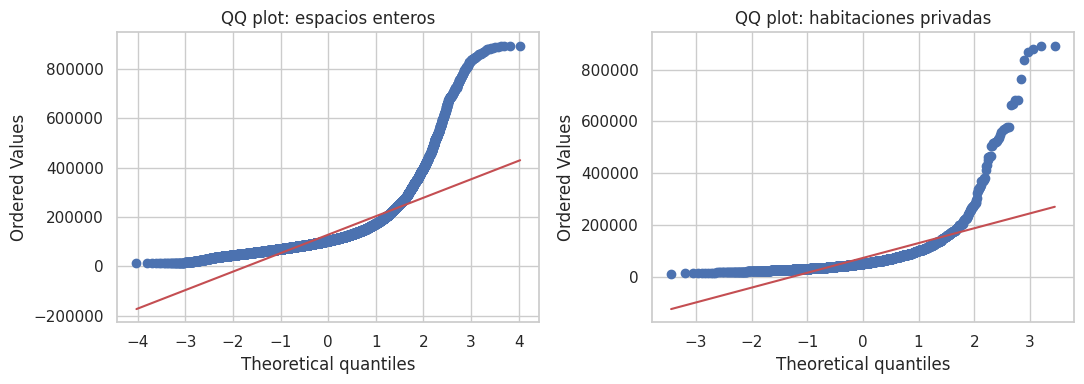

Shapiro enteros (n=5.000): W = 0.644, p = 5.59e-73
Shapiro privadas (n=2,446): W = 0.514, p = 2.65e-63
Levene: estadístico = 66.6, p = 3.49e-16
Desvío enteros: 91,718 | privadas: 79,986


In [68]:
precios_entero = data_precios.loc[data_precios["room_type"] == "Entire home/apt", "price"]
precios_privada = data_precios.loc[data_precios["room_type"] == "Private room", "price"]

# Normalidad: QQ plots (precio sin transformar)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
stats.probplot(precios_entero, dist="norm", plot=axes[0])
axes[0].set_title("QQ plot: espacios enteros")
stats.probplot(precios_privada, dist="norm", plot=axes[1])
axes[1].set_title("QQ plot: habitaciones privadas")
plt.tight_layout()
plt.show()

# Shapiro-Wilk (submuestra de 5.000 en enteros; las privadas entran completas)
sh_e = stats.shapiro(precios_entero.sample(5000, random_state=42))
sh_p = stats.shapiro(precios_privada)

# Homocedasticidad: Levene centrado en la mediana (robusto a asimetría y valores extremos)
lev = stats.levene(precios_entero, precios_privada, center="median")

print(f"Shapiro enteros (n=5.000): W = {sh_e.statistic:.3f}, p = {sh_e.pvalue:.2e}")
print(f"Shapiro privadas (n={len(precios_privada):,}): W = {sh_p.statistic:.3f}, p = {sh_p.pvalue:.2e}")
print(f"Levene: estadístico = {lev.statistic:.1f}, p = {lev.pvalue:.2e}")
print(f"Desvío enteros: {precios_entero.std():,.0f} | privadas: {precios_privada.std():,.0f}")

**Resultados.**

* **Independencia:** no se cumple, porque los anuncios de un mismo anfitrión se parecen entre sí y algunos anfitriones ofrecen ambos tipos de alojamiento. Se verifica repitiendo el test con un solo anuncio por anfitrión.
* **Normalidad:** no se cumple. Los QQ plots muestran una cola derecha muy pesada en ambos grupos: los precios más altos son varias veces mayores a lo esperado bajo normalidad. Shapiro-Wilk lo confirma ($W = 0{,}644$ en espacios enteros y $W = 0{,}514$ en habitaciones privadas, $p < 0{,}001$ en ambos).
* **Homocedasticidad:** no se cumple. Levene rechaza la igualdad de varianzas ($p < 0{,}001$), con desvíos de ≈ 91.700 en espacios enteros y ≈ 80.000 en habitaciones privadas.

**Conclusión.** Ninguno de los tres supuestos se cumple estrictamente, pero esto no invalida el contraste:

* La falta de normalidad no es crítica porque el contraste es sobre promedios y las muestras son grandes (24.870 y 2.446 anuncios). Por el teorema central del límite, el promedio es aproximadamente normal aunque los precios no lo sean.
* Las varianzas distintas no son un problema porque el t de Welch no supone varianzas iguales.
* La dependencia entre anuncios de un mismo anfitrión se evalúa repitiendo el test con un solo anuncio por anfitrión, donde los anuncios sí son independientes.

No se utiliza una prueba no paramétrica (Mann-Whitney o Kruskal-Wallis) porque estas comparan rangos y no promedios: el enunciado se refiere a promedios y a "el doble", algo que esas pruebas no pueden contrastar directamente. Cambiar de prueba implicaría cambiar la hipótesis, pasando de promedios a precios típicos.

Por lo tanto, se aplica el t de Welch unilateral sobre `price` sin transformar, comparando el promedio de los espacios enteros con el **doble** del de las habitaciones privadas.

In [69]:
def welch_doble(d, titulo):
    entero = d.loc[d["room_type"] == "Entire home/apt", "price"]
    privada = d.loc[d["room_type"] == "Private room", "price"]

    # t de Welch unilateral: promedio de enteros vs. el doble del promedio de privadas
    res = stats.ttest_ind(entero, 2 * privada, equal_var=False, alternative="greater")

    print(titulo)
    print(f"  n entero = {len(entero):,} | n privada = {len(privada):,}")
    print(f"  Promedio entero: {entero.mean():,.0f} | privada: {privada.mean():,.0f} | Razón: {entero.mean() / privada.mean():.2f}")
    print(f"  t de Welch = {res.statistic:.2f} | p unilateral = {res.pvalue:.4f}\n")

# Versión 1: todos los anuncios
welch_doble(data_precios, "Todos los anuncios")

# Versión 2: un anuncio por anfitrión, elegido al azar: así las observaciones son independientes
# y cada anfitrión queda en un solo grupo
un_por_host = data_precios.sample(frac=1, random_state=42).drop_duplicates("host_id")
welch_doble(un_por_host, "Un anuncio por anfitrión")

Todos los anuncios
  n entero = 24,870 | n privada = 2,446
  Promedio entero: 128,381 | privada: 72,603 | Razón: 1.77
  t de Welch = -5.12 | p unilateral = 1.0000

Un anuncio por anfitrión
  n entero = 12,404 | n privada = 1,084
  Promedio entero: 117,366 | privada: 70,894 | Razón: 1.66
  t de Welch = -4.71 | p unilateral = 1.0000



#### Conclusión del contraste

| Versión | n entero | n privada | Prom. entero | Prom. privada | Razón | t de Welch | p unilateral |
|---|---|---|---|---|---|---|---|
| Todos los anuncios | 24.870 | 2.446 | 128.381 | 72.603 | 1,77 | −5,12 | 1,0000 |
| Un anuncio por anfitrión | 12.404 | 1.084 | 117.366 | 70.894 | 1,66 | −4,71 | 1,0000 |

**Decisión.** En ambas versiones el p-valor unilateral es ≈ 1, mayor que $\alpha = 0{,}05$, por lo que no se rechaza $H_0$.

**Conclusión.** Los datos no respaldan el enunciado: el precio promedio de un espacio entero no llega al doble del de una habitación privada. La razón entre promedios es 1,77 con todos los anuncios y 1,66 con un anuncio por anfitrión. Los estadísticos $t$ son negativos en ambos casos, es decir, la estimación apunta en sentido contrario a $H_1$. Por eso la decisión no depende de la forma exacta de la distribución de los precios, y tampoco cambia al eliminar la dependencia entre anuncios de un mismo anfitrión.

**Cómo leer el resultado.** El contraste compara el promedio de los espacios enteros con el doble del de las habitaciones privadas. Un $t$ negativo significa que ese promedio queda por debajo del doble. El p-valor es ≈ 1 porque $H_1$ pide lo contrario.

**Limitaciones.**

* La diferencia de precios es una asociación: los espacios enteros también tienen mayor capacidad y equipamiento, no solo privacidad.
* El enunciado se refiere a promedios, y por eso se concluye sobre ellos. En el análisis descriptivo, la razón de medianas fue 2,03: el espacio entero "típico" cuesta alrededor del doble, pero el promedio no llega porque las habitaciones privadas tienen una cola de precios altos que sube su promedio.
* Con un anuncio por anfitrión se usan menos anuncios y cada anfitrión pesa lo mismo, por eso la razón baja de 1,77 a 1,66. La conclusión es la misma.

### Hipotesis 6 (multivariada): Independencia y precio a igual capacidad

### Planteo

__Enunciado__: A igual capacidad de huéspedes, un alojamiento se alquila más caro si garantiza mayor independencia: una cama para cada persona (no compartir colchón), mayor cantidad de baños por huésped y reserva automática.

__Variables.__

* __Dependiente__: `price`, cuantitativa continua (se modela su logaritmo).
* __Control (igual capacidad)__: `accommodates`, cuantitativa discreta, tratada como categórica (un valor por cada capacidad).
* __Independientes de interés__:
    * `cama_propia`: vale 1 si `beds` ≥ `accommodates` (hay al menos una cama por huésped) y 0 en caso contrario. Cualitativa dicotómica.
    * `banos_por_huesped`: `bathrooms` / `accommodates`. Cuantitativa continua.
    * `instant_bookable` (reserva automática): cualitativa dicotómica. No se puede evaluar porque la columna no tiene datos.

__Justificación y valor generado:__ Para un anfitrión, saber si ofrecer más independencia (una cama por persona, más baños por huésped) se traduce en un precio más alto ayuda a decidir si vale la pena invertir en ello. Se compara a igual capacidad para no confundir independencia con tamaño: un alojamiento para 8 personas es más caro que uno para 2 por tener más lugar, no por ser más independiente. Los resultados se interpretan como asociaciones y no como efectos causales.

### Planteo del Contraste

Se utiliza regresión lineal múltiple porque permite estimar el efecto de cada variable manteniendo constantes las demás, que es lo que significa "a igual capacidad", y contrastar cada efecto con un test t sobre su coeficiente. No se usan técnicas de reducción de dimensión (PCA, t-SNE, UMAP) ni clustering, porque interesa el efecto de cada variable por separado y no resumirlas ni agruparlas.

Se ajusta una regresión lineal múltiple:

$\ln(precio_i) = \beta_0 + \gamma_{capacidad_i} + \beta_2\,cama_i + \beta_3\,banos_i + \varepsilon_i$

donde $\gamma$ toma un valor distinto para cada capacidad (1, 2, 3, ... 16 huéspedes). Así, cada coeficiente compara alojamientos con la misma capacidad.

Cada coeficiente se interpreta manteniendo constantes los demás, es decir, a igual capacidad. Cada afirmación se contrasta por separado, con un test t unilateral sobre su coeficiente:

* **Cama para cada persona:** $H_0: \beta_2 \leq 0$ vs. $H_1: \beta_2 > 0$
* **Más baños por huésped:** $H_0: \beta_3 \leq 0$ vs. $H_1: \beta_3 > 0$
* **Reserva automática:** no evaluable (sin datos).

* **Nivel de significancia:** $\alpha = 0{,}05$.

In [70]:
data_c = df_copia.copy()
data_c["camas_por_huesped"] = data_c["beds"] / data_c["accommodates"]
data_c["banos_por_huesped"] = data_c["bathrooms"] / data_c["accommodates"]

# Valores imposibles: más de 2 camas o más de 2 baños por huésped
validos = (data_c["camas_por_huesped"] <= 2) & (data_c["banos_por_huesped"] <= 2)
print(f"Se descartan {(~validos).sum()} anuncios ({(~validos).mean():.1%})")
data_c = data_c[validos].copy()

data_c["cama_propia"] = (data_c["beds"] >= data_c["accommodates"]).astype(int)   # 1 = al menos una cama por huésped
data_c["log_price"] = np.log(data_c["price"])

print(f"Anuncios para (c): {len(data_c):,} | con cama propia: {data_c['cama_propia'].mean():.1%}")
print(pd.crosstab(data_c["accommodates"], data_c["cama_propia"]))

Se descartan 293 anuncios (1.1%)
Anuncios para (c): 27,287 | con cama propia: 17.5%
cama_propia       0     1
accommodates             
1                 0  1109
2             11225  2053
3              4117   702
4              5010   582
5               910   127
6               760    93
7               138     9
8               171    31
9                37    10
10               52    17
11               14     5
12               22     8
13                4     1
14                9     3
15               13     1
16               25    29


**Preparación de variables.** Se calculan `camas_por_huesped` y `banos_por_huesped` (camas y baños divididos por la capacidad). Algunos anuncios tienen valores imposibles (hasta 25 camas o 20 baños por huésped), que se interpretan como errores de carga. Se descartan los que superan 2 camas o 2 baños por huésped: **293 anuncios (1,1 %)**, quedando **27.287** para el análisis de (c). Esto se hace sobre una copia de la base, por lo que el resto del trabajo no cambia.

La variable `cama_propia` vale 1 cuando hay al menos una cama por huésped (`beds` ≥ `accommodates`) y 0 en caso contrario. Lo cumple el 17,5 % de los anuncios.

La tabla cruzada muestra cómo se reparte `cama_propia` según la capacidad:

* Los alojamientos para 1 huésped siempre tienen cama propia (1.109 anuncios, todos con valor 1). Al no haber variación, no aportan información sobre el efecto de la cama.
* Entre 2 y 6 huéspedes (25.579 anuncios, 94 % del total) hay casos de ambos tipos en cantidad suficiente, por ejemplo 11.225 sin cama propia y 2.053 con ella para 2 huéspedes. Ahí se puede comparar.
* Los de 7 o más huéspedes son pocos (599 anuncios, 2,2 %) y con muy pocos casos de cama propia, por lo que aportan poco a la comparación.

Por eso la capacidad se controla por categorías: cada comparación se hace entre alojamientos con la misma capacidad.

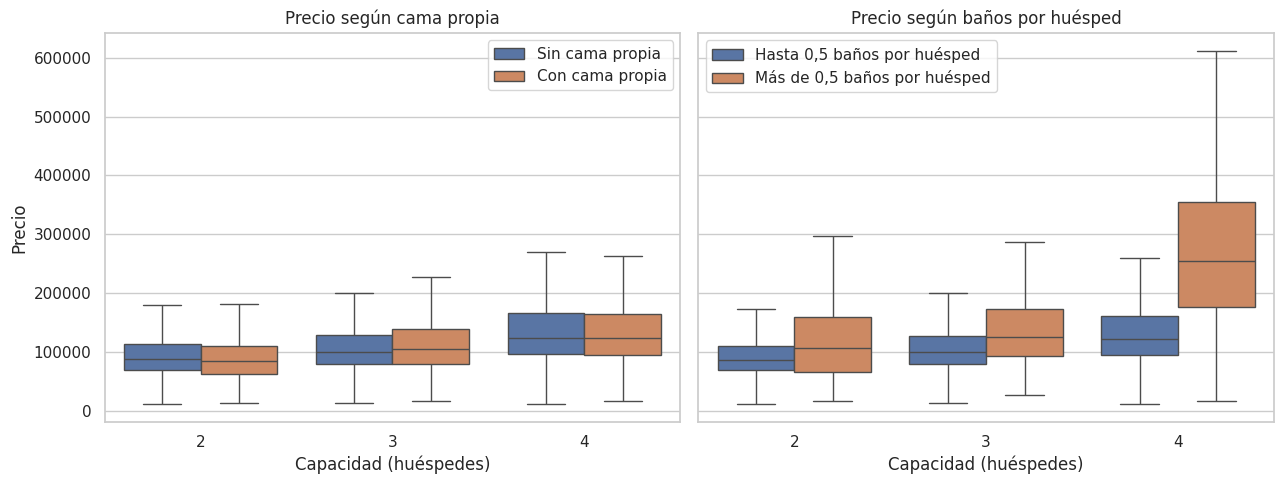

                                  n   mediana  promedio
accommodates cama                                      
2            Con cama propia   2053   84678.0   96954.0
             Sin cama propia  11225   89435.0  102304.0
3            Con cama propia    702  104952.0  123137.0
             Sin cama propia   4117  100760.0  114903.0
4            Con cama propia    582  124688.0  144848.0
             Sin cama propia   5010  123752.0  145165.0
                                               n   mediana  promedio
accommodates banos                                                  
2            Hasta 0,5 baños por huésped   12108   87871.0   98909.0
             Más de 0,5 baños por huésped   1170  107191.0  128054.0
3            Hasta 0,5 baños por huésped    4568  100391.0  114153.0
             Más de 0,5 baños por huésped    251  126431.0  151578.0
4            Hasta 0,5 baños por huésped    5423  122381.0  141223.0
             Más de 0,5 baños por huésped    169  254198.0  270560.0


In [71]:
# Solo capacidades 2, 3 y 4 (las de 1 huésped no tienen variación en cama propia)
g = data_c[data_c["accommodates"].isin([2, 3, 4])].copy()
g["cama"] = g["cama_propia"].map({0: "Sin cama propia", 1: "Con cama propia"})
g["banos"] = np.where(g["banos_por_huesped"] > 0.5, "Más de 0,5 baños por huésped", "Hasta 0,5 baños por huésped")

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

sns.boxplot(data=g, x="accommodates", y="price", hue="cama",
            hue_order=["Sin cama propia", "Con cama propia"], showfliers=False, ax=axes[0])
axes[0].set_title("Precio según cama propia")

sns.boxplot(data=g, x="accommodates", y="price", hue="banos",
            hue_order=["Hasta 0,5 baños por huésped", "Más de 0,5 baños por huésped"], showfliers=False, ax=axes[1])
axes[1].set_title("Precio según baños por huésped")

for ax in axes:
    ax.set_xlabel("Capacidad (huéspedes)")
    ax.legend(title="")
axes[0].set_ylabel("Precio")
plt.tight_layout()
plt.show()

# Tablas de apoyo: cantidad, mediana y promedio en cada grupo
print(g.groupby(["accommodates", "cama"])["price"].agg(n="count", mediana="median", promedio="mean").round(0))
print(g.groupby(["accommodates", "banos"])["price"].agg(n="count", mediana="median", promedio="mean").round(0))

**Análisis gráfico.** Cada comparación se hace entre alojamientos de la misma capacidad (2, 3 y 4 huéspedes), con el precio en escala original y sin valores atípicos.

* **Cama propia:** no se ve una diferencia consistente. Las cajas son casi iguales y la dirección cambia según la capacidad: con 2 huéspedes la mediana es menor con cama propia (84.678 contra 89.435), con 3 es algo mayor (104.952 contra 100.760) y con 4 prácticamente no cambia (124.688 contra 123.752). No hay indicio de que garantizar una cama por persona encarezca el alquiler.
* **Baños por huésped:** en las tres capacidades, los alojamientos con más de 0,5 baños por huésped tienen precios más altos. La mediana sube 22 % con 2 huéspedes (107.191 contra 87.871) y 26 % con 3 (126.431 contra 100.391). Con 4 huéspedes se duplica (254.198 contra 122.381), aunque ese grupo tiene solo 169 anuncios y una dispersión muy grande, por lo que conviene tomarlo con cautela.

**Lectura.** Los gráficos dan un indicio a favor de la parte de los baños y ninguno a favor de la cama propia. Es solo una exploración: la regresión permite contrastarlo formalmente y mantener constantes las demás variables. Además, los alojamientos con más baños por huésped pueden ser también más grandes o de mayor categoría, por lo que la diferencia no se interpreta como un efecto causal.

n = 27,287 | R² = 0.305 | R² ajustado = 0.304


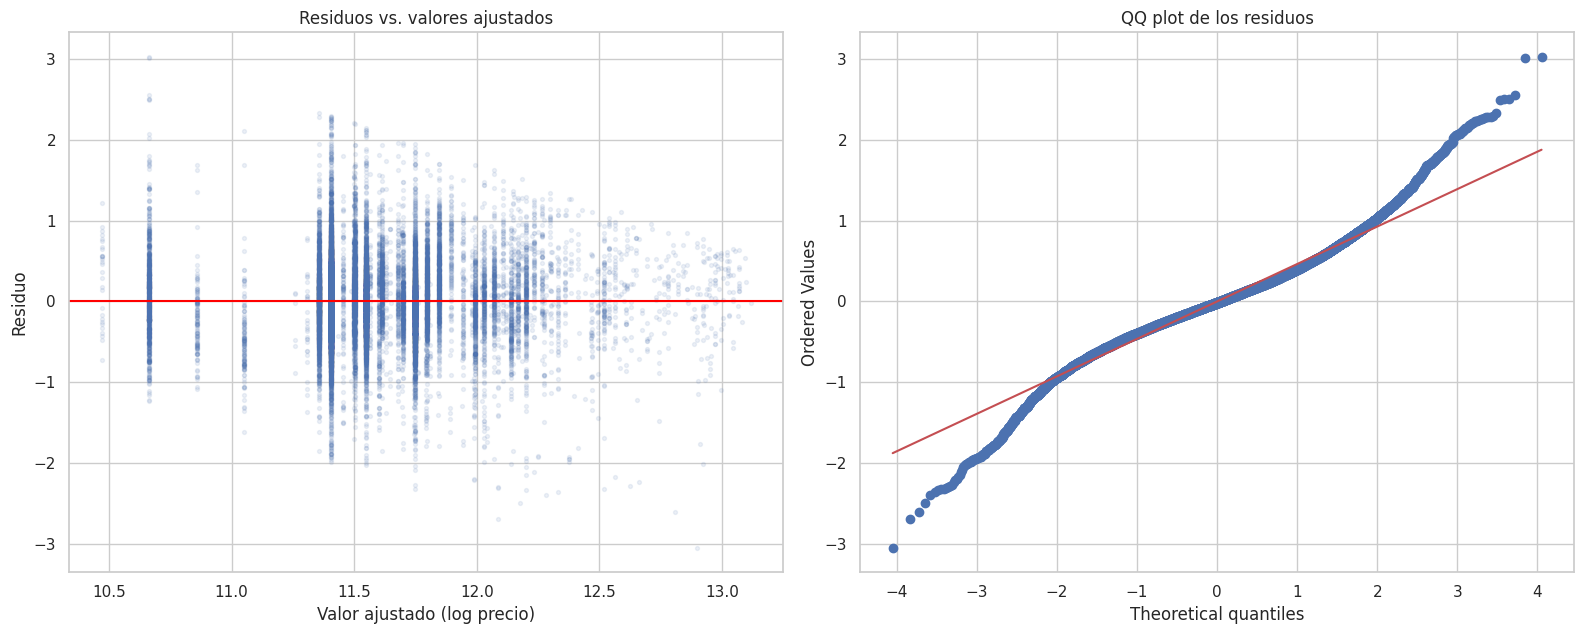

Breusch-Pagan: LM = 992.0, p = 4.74e-200
Shapiro-Wilk (5.000): W = 0.973, p = 1.24e-29
Durbin-Watson: 1.60 | ordenado por host_id: 1.37
cama_propia          1.26
banos_por_huesped    2.59
dtype: float64


In [72]:
# Modelo: log(precio) ~ capacidad (por categorías) + cama propia + baños por huésped
m = smf.ols("log_price ~ C(accommodates) + cama_propia + banos_por_huesped", data=data_c).fit()
resid, ajust = m.resid, m.fittedvalues
print(f"n = {int(m.nobs):,} | R² = {m.rsquared:.3f} | R² ajustado = {m.rsquared_adj:.3f}")

# --- Gráficos: linealidad, homocedasticidad y normalidad ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

axes[0].scatter(ajust, resid, alpha=0.1, s=8)
axes[0].axhline(0, color="red")
axes[0].set(title="Residuos vs. valores ajustados", xlabel="Valor ajustado (log precio)", ylabel="Residuo")

stats.probplot(resid, dist="norm", plot=axes[1])
axes[1].set_title("QQ plot de los residuos")
plt.tight_layout()
plt.show()

# --- Tests ---
bp = het_breuschpagan(resid, m.model.exog)                                   # homocedasticidad
sh = stats.shapiro(resid.sample(5000, random_state=42))                      # normalidad
dw_orig = durbin_watson(resid)                                               # independencia
dw_host = durbin_watson(data_c.assign(resid=resid).sort_values("host_id")["resid"])

print(f"Breusch-Pagan: LM = {bp[0]:.1f}, p = {bp[1]:.2e}")
print(f"Shapiro-Wilk (5.000): W = {sh.statistic:.3f}, p = {sh.pvalue:.2e}")
print(f"Durbin-Watson: {dw_orig:.2f} | ordenado por host_id: {dw_host:.2f}")

# --- Multicolinealidad: VIF de las dos variables de interés ---
X = m.model.exog
vif = pd.Series([variance_inflation_factor(X, i) for i in range(X.shape[1])], index=m.model.exog_names)
print(vif[["cama_propia", "banos_por_huesped"]].round(2))

**Resultados.** El modelo explica el 30,5 % de la variabilidad del logaritmo del precio ($R^2$ ajustado = 0,304).

* **Linealidad:** se cumple en lo esencial. Los residuos se distribuyen alrededor de 0 sin una curvatura marcada respecto de los valores ajustados.
* **Independencia:** no se cumple. Durbin-Watson vale 1,60 con el orden original y 1,37 al ordenar por `host_id`, ambos menores que 2, lo que indica que los errores de anuncios de un mismo anfitrión están correlacionados (correlación ≈ 0,3).
* **Homocedasticidad:** no se cumple. Breusch-Pagan rechaza ($p < 0{,}001$) y en el gráfico la dispersión de los residuos es menor en los valores ajustados más altos.
* **Normalidad:** se cumple solo de forma aproximada. Shapiro-Wilk rechaza ($W = 0{,}973$, $p < 0{,}001$), pero $W$ está cerca de 1 y el QQ plot sigue la recta en el centro, con colas algo más pesadas que las de una normal.
* **Multicolinealidad:** se cumple. Los VIF son 1,26 para `cama_propia` y 2,59 para `banos_por_huesped`, muy por debajo de 5.

**Conclusión.** Se cumplen la linealidad y la ausencia de multicolinealidad. No se cumplen la independencia ni la homocedasticidad, y la normalidad solo aproximadamente. Esto no sesga los coeficientes estimados, pero sí puede volver poco precisos sus errores estándar y p-valores. Con 27.287 anuncios la falta de normalidad no es crítica, y la dependencia entre anuncios de un mismo anfitrión se verifica repitiendo la regresión con un solo anuncio por anfitrión.

In [73]:
def ajustar(d, titulo):
    m = smf.ols("log_price ~ C(accommodates) + cama_propia + banos_por_huesped", data=d).fit()
    filas = []
    for v in ["cama_propia", "banos_por_huesped"]:
        b, p2 = m.params[v], m.pvalues[v]
        p_uni = p2 / 2 if b > 0 else 1 - p2 / 2          # unilateral: H1 es coef > 0
        lo, hi = m.conf_int().loc[v]
        filas.append({"versión": titulo, "variable": v, "n": int(m.nobs), "coef": b, "EE": m.bse[v],
                      "t": m.tvalues[v], "p unilateral": p_uni, "IC_inf": lo, "IC_sup": hi})
    return pd.DataFrame(filas)

# Un anuncio por anfitrión, elegido al azar
un_por_host = data_c.sample(frac=1, random_state=42).drop_duplicates("host_id")

res = pd.concat([ajustar(data_c, "Todos los anuncios"),
                 ajustar(un_por_host, "Un anuncio por anfitrión")]).set_index(["versión", "variable"])
res.round(4)

n    coef      EE        t  \
versión                  variable                                            
Todos los anuncios       cama_propia        27287 -0.0499  0.0084  -5.9487   
                         banos_por_huesped  27287  0.3882  0.0205  18.9427   
Un anuncio por anfitrión cama_propia        13488 -0.0288  0.0114  -2.5352   
                         banos_por_huesped  13488  0.5752  0.0302  19.0480   

                                            p unilateral  IC_inf  IC_sup  
versión                  variable                                         
Todos los anuncios       cama_propia              1.0000 -0.0664 -0.0335  
                         banos_por_huesped        0.0000  0.3480  0.4284  
Un anuncio por anfitrión cama_propia              0.9944 -0.0511 -0.0065  
                         banos_por_huesped        0.0000  0.5160  0.6344

**Resultados y decisión.**

Se ajustó la regresión lineal múltiple planteada, con `ln(precio)` como respuesta, la capacidad (`accommodates`) como control categórico, `cama_propia` y `banos_por_huesped`. Cada coeficiente se contrastó con el test t unilateral (H0: β ≤ 0 contra H1: β > 0, con β₂ para la cama propia y β₃ para los baños por huésped). Como en las demás hipótesis, el ajuste se hizo con todos los anuncios (n = 27.287) y con un anuncio por anfitrión (n = 13.488).

| Variable | Efecto % (todos / uno por anfitrión) | IC 95 % del efecto (todos / uno por anfitrión) | p unilateral (todos / uno por anfitrión) | Decisión (α = 0,05) |
|---|---|---|---|---|
| Cama propia | −4,9 % / −2,8 % | (−6,4 ; −3,3) / (−5,0 ; −0,6) | ≈ 1 / 0,994 | No se rechaza H0 |
| Baños por huésped (+0,5) | +21,4 % / +33,3 % | (19,0 ; 23,9) / (29,4 ; 37,3) | < 0,001 / < 0,001 | Se rechaza H0 |

(Efecto % = (exp(β) − 1)·100, a igual capacidad. Para los baños se toma un aumento de 0,5 baños por huésped, por ejemplo un alojamiento para 2 con 2 baños en lugar de 1.)

**Conclusión.** La parte de los baños se confirma: a igual capacidad, tener más baños por huésped se asocia con un precio mayor, y la conclusión es la misma con todos los anuncios y con uno por anfitrión. La parte de la cama propia no se confirma: el p unilateral es ≈ 1, así que no hay evidencia de que garantizar una cama por persona encarezca el alquiler. Además, el coeficiente es negativo y su intervalo excluye el 0, es decir, hay una asociación negativa chica (entre −6 % y −1 %). La reserva automática no pudo evaluarse porque la columna no tiene datos. Por lo tanto, **H6 se confirma solo en parte**.

**Limitaciones.**
- Es una asociación, no causalidad: los alojamientos con más baños por huésped pueden ser también de mayor categoría.
- La magnitud del efecto de los baños cambia entre versiones (+21 % contra +33 %), aunque no el signo ni la decisión. Por eso se informa el rango.
- `cama_propia` compara camas con huéspedes: una cama doble cuenta como una sola, por lo que no mide exactamente "no compartir colchón".
- `beds` y `bathrooms` tenían nulos (≈ 9 % y 12 %) imputados con la mediana por capacidad, lo que debilita el contraste de ambas variables.
- La heterocedasticidad y la dependencia entre anuncios del mismo anfitrión pueden volver imprecisos los errores estándar. La verificación con un anuncio por anfitrión da la misma conclusión.